# Porter: Delivery Time Estimation using Neural Networks

**Objective:** Estimate how many minutes a delivery will take, using what was ordered, where it was ordered from, and how many delivery partners are available. A Random Forest is built as the baseline and a neural network is compared against it.

**Flow of the case study:**

```
Problem  -->  Data  -->  Preprocessing  -->  Visualisation & Outliers  -->  Random Forest  -->  Neural Network  -->  Compare
```

## Stages Overview

1. Stage 1: Problem Understanding, Data Import & Structure Analysis
2. Stage 2: Data Preprocessing & Feature Engineering
3. Stage 3: Data Visualization, Outlier Detection & Cleaning
4. Stage 4: Baseline Model with Random Forest
5. Stage 5: Regression with Neural Networks

## How You're Evaluated (100 Marks)

| Section | Marks |
|:--|:--:|
| Problem Statement, Data Import & Structure Analysis | 10 |
| Data Preprocessing & Feature Engineering | 30 |
| Data Visualization, Outlier Detection & Cleaning | 20 |
| Model Training with Random Forest | 10 |
| Regression with Neural Networks | 30 |
| **Total** | **100** |

## Contents

The sections, points and tasks follow the **Evaluation Criteria (100 points)** of the problem brief and the five stages of the case-study walkthrough (27 tasks, 10 brief questions).

| # | Section | Points | Tasks |
|:--:|:--|:--:|:--|
| 1 | [Problem Statement, Data Import and Data Structure Analysis](#sec1) | 10 | 1.1 to 1.5 |
| 2 | [Data Preprocessing and Feature Engineering](#sec2) | 30 | 2.1 to 2.6 |
| 3 | [Data Visualization, Outlier Detection and Cleaning](#sec3) | 20 | 3.1 to 3.6 |
| 4 | [Model Training with Random Forest](#sec4) | 10 | 4.1 to 4.4 |
| 5 | [Regression with Neural Networks](#sec5) | 30 | 5.1 to 5.6 |
| | **Total** | **100** | **27 tasks** |

**The 10 questions and where each is answered** (each question is also repeated above its answer):

| # | Question | Answered in |
|:--:|:--|:--:|
| 1 | Defining the problem statements and where can this and modifications of this be used? | 1.1 |
| 2 | List 3 functions the pandas datetime provides with one line explanation. | 1.4 |
| 3 | Short note on datetime, timedelta, timespan(period) | 1.5 |
| 4 | Why do we need to check for outliers in our data? | 3.2 |
| 5 | Name 3 outlier removal methods? | 3.3 |
| 6 | What classical machine learning methods can we use other than random forest for regression? | 4.4 |
| 7 | Why is scaling required for neural networks? | 5.1 |
| 8 | Briefly explain your choice of optimizer. | 5.3 |
| 9 | Which activation function did you use and why? | 5.2 |
| 10 | Why does a neural network perform well on a large dataset? | 5.6 |

## Process

1. Import the data and understand the structure of the data.
2. Usual exploratory analysis steps like checking the structure & characteristics of the dataset.
3. Data preprocessing
    - Cleaning of data
    - Feature engineering: creating the target column time taken in each delivery from order timestamp (created_at) and delivery timestamp (actual_delivery_time)
    - Getting hour of day from the order time and also the day of the week
    - Understanding pandas datetime data type and what function it provides by default
    - Get delivery time in minutes
    - Handling null values
    - Encoding categorical columns
4. Data visualization and cleaning
    - Visualize various columns for better understanding Countplots, scatterplots
    - Check if the data contains outliers
    - Removing outliers by any method
    - Plotting the data again to see if anything has improved
5. Split the data in train and test
6. Creating a baseline model using random forest
7. Checking its various metrics like mse, rsme, mae
8. Scaling the data for neural networks.
9. Creating a simple neural network
10. Trying different configurations
11. Understanding different activation functions, optimizers and other hyperparameters.
12. Training the neural network for required amount of epochs
13. Plotting the losses and checking the accuracy of the model
14. Comparing the results of neural network and random forest

<a id="sec1"></a>

# Section 1: Problem Statement, Data Import and Data Structure Analysis (10 points)

### Objective and Tasks of this Section

**Stage 1 of 5 · 5 Tasks: Problem Understanding, Data Import & Structure Analysis**

**Objective:** You will frame the business problem Porter is trying to solve, load the delivery dataset, and get familiar with its structure before making any changes to it.

| Task | What to do | Hint |
|:--|:--|:--|
| **Task 1.1** | State the business problem in your own words — what is Porter trying to predict, and why does it matter to the business? Then note one other scenario (inside or outside Porter) where a similar delivery/ETA prediction model could be reused. | Think about what decision this predicted number feeds into downstream, and who sees it (the customer, the driver-partner, or an internal ops team). |
| **Task 1.2** | Import the dataset into your notebook environment and load it into a pandas DataFrame. | Think about how you'd pull a file shared via a Google Drive link directly into a Colab session, and which pandas function reads a CSV into a DataFrame. |
| **Task 1.3** | Inspect the structure of the data — shape, column names, and data types — and note which columns look like they will need type conversion before any feature engineering. | Think about which columns look like text/object type but actually represent points in time. |
| **Task 1.4** | List three functions or accessors that pandas' datetime handling provides, with a one-line explanation of what each one does. | Think about the different things you'd want to do with a timestamp column — parsing it, pulling out a component of it, and taking a difference between two of them. |
| **Task 1.5** | Write a short note distinguishing a datetime, a timedelta, and a Period/timespan object. | Think about the difference between a single point in time, a duration between two points, and a fixed span like 'March 2024'. |

**Evaluation criteria of this section (10 points):**

| Criterion | Done in |
|:--|:--|
| Defining problem statement, importing the data and data structure analysis | 1.1 to 1.5 |

Each task below is marked in its heading, for example `(Task 1.1)`.

---


## 1.1 Problem Statement (Task 1.1, Brief Question 1)

### Problem Statement

Porter is India's Largest Marketplace for Intra-City Logistics. Leader in the country's \$40 billion intra-city logistics market, Porter strives to improve the lives of 1,50,000+ driver-partners by providing them with consistent earning & independence. Currently, the company has serviced 5+ million customers

Porter works with a wide range of restaurants for delivering their items directly to the people.

Porter has a number of delivery partners available for delivering the food, from various restaurants and wants to get an estimated delivery time that it can provide the customers on the basis of what they are ordering, from where and also the delivery partners.

This dataset has the required data to train a regression model that will do the delivery time estimation, based on all those features

**Dataset:** https://drive.google.com/file/d/1kkgBGldeswHBgVKEJiqqG7VZvqZNMc-5/view?usp=share_link

### Business Case

Porter is India's largest marketplace for intra-city logistics. It helps 1,50,000+ driver-partners earn consistently and has served 5+ million customers.

Porter also works with a wide range of restaurants for delivering their food directly to people. There are many delivery partners available, and the food comes from many different restaurants.

You are a data scientist at Porter. Your job is to give every customer an **estimated delivery time** at the moment they place an order. The estimate should depend on:

- **what** they are ordering (number of items, price),
- **where** they are ordering from (market, type of restaurant, how the order was placed),
- **who can deliver it** right now (delivery partners on duty, partners already busy, orders waiting).

**Dataset link:** https://drive.google.com/file/d/1kkgBGldeswHBgVKEJiqqG7VZvqZNMc-5/view?usp=share_link

Each row of the dataset is one delivery. Let's start by defining the problem properly.

### Defining the Problem Statement (Brief Question 1)

> **Brief Question 1:** *Defining the problem statements and where can this and modifications of this be used?*


**What do we want to predict?** The number of minutes a delivery will take, from the time the order is placed to the time it is delivered.

**Why does it matter?**

- **Customer:** decides whether to order, and whether to trust Porter. A promise that is too optimistic and then missed hurts trust. A promise that is too pessimistic loses orders.
- **Driver-partner:** helps plan trips and earnings fairly.
- **Operations team:** helps decide how many partners to keep on shift, and warns early when a market is short of partners.

**How do we turn it into a machine learning problem?**

| Item | Choice |
|:--|:--|
| Type of problem | **Regression**, because the answer is a number (minutes), not a class |
| Target | `time_taken_mins` = `actual_delivery_time` - `created_at`, in minutes (we create it in Section 2) |
| Features | Only what is known when the order is placed |
| Metrics | MAE (average error in minutes), RMSE, R² |
| Models | Random Forest as the baseline, then a neural network, compared on the same test data |

**Important:** `actual_delivery_time` is only known after the delivery, and it is the source of our target. If we used it as a feature, the model would simply read the answer. This is called **data leakage**.

### Where can this idea (and modifications of it) be used?

**Inside Porter**

- Delivery time for goods and parcel trips, not only food.
- Pickup time: how long until a driver-partner reaches the restaurant or the sender.
- Setting delivery promises and prices when partners are scarce.
- Deciding how many partners to keep on shift in each market and hour.

**Outside Porter**

- Food delivery and quick-commerce apps (the same features: items, price, restaurant, rider supply).
- E-commerce last-mile delivery, courier and freight companies.
- Ride-hailing arrival and trip-duration estimates.
- Field-service appointment windows and ambulance response times.

**Modifications**

- Predict a range (for example "35 to 50 minutes") instead of a single number.
- Turn it into classification: "will this order be late compared to its promise?" (the QuickCart example in the Hyperparameter Tuning class does exactly this).
- Predict delivery time and delivery cost together with one multi-output network.
- Add live features such as traffic and weather, and retrain regularly because conditions change.

### One Other Scenario in Detail: Ride-Hailing Arrival Time

A ride-hailing app has the same problem in a different business. When a customer books a cab, the app must say "your driver arrives in 6 minutes".

| | Porter delivery time | Ride-hailing arrival time |
|:--|:--|:--|
| What is predicted | Minutes from order to delivery | Minutes from booking to pickup |
| Information known at request time | Items, price, restaurant, partners on duty, partners busy, orders waiting | Pickup distance, drivers nearby, drivers busy, requests waiting, time of day |
| Type of problem | Regression | Regression |
| Same reasoning | Supply (partners) versus demand (orders) drives the waiting time | Supply (drivers) versus demand (requests) drives the waiting time |

The data preparation, the Random Forest baseline and the neural network in this notebook would carry over with only the column names changed.

## 1.2 Importing the Data (Task 1.2)

### Setup: Import Libraries

We start with the libraries we need for this part: `pandas` for tabular data, `numpy` for numerical work and `matplotlib` and `seaborn` for charts. We also fix the random seed to 42 so that every run of the notebook gives the same results. The two colours defined here (blue and orange) are used in every chart.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

np.random.seed(42)

BLUE, ORANGE, AQUA, YELLOW, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8a85"
sns.set_theme(style="whitegrid", palette=[BLUE, ORANGE, AQUA, YELLOW])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

### Data Dictionary

Each row in this file corresponds to one unique delivery. Each column corresponds to a feature as explained below

| # | Column Name | Description |
|:--:|:--|:--|
| 1 | market_id | integer id for the market where the restaurant lies |
| 2 | created_at | the timestamp at which the order was placed |
| 3 | actual_delivery_time | the timestamp when the order was delivered |
| 4 | store_primary_category | category for the restaurant |
| 5 | order_protocol | integer code value for order protocol(how the order was placed ie: through porter, call to restaurant, pre booked, third part etc) |
| 6 | total_items subtotal | final price of the order |
| 7 | num_distinct_items | the number of distinct items in the order |
| 8 | min_item_price | price of the cheapest item in the order |
| 9 | max_item_price | price of the costliest item in order |
| 10 | total_onshift_partners | number of delivery partners on duty at the time order was placed |
| 11 | total_busy_partners | number of delivery partners attending to other tasks |
| 12 | total_outstanding_orders | total number of orders to be fulfilled at the moment |

The file we actually have uses slightly different names (for example `total_onshift_dashers`) and has two more columns. The next table describes the real columns.

### Data Description

| Id | Features | Description |
| :-- | :-- | :-- |
|01| **market_id** | Integer id of the market where the restaurant lies |
|02| **created_at** | The timestamp at which the order was placed |
|03| **actual_delivery_time** | The timestamp at which the order was delivered |
|04| **store_primary_category** | Category of the restaurant |
|05| **order_protocol** | Integer code for how the order was placed (through Porter, call to the restaurant, pre-booked, third party, ...) |
|06| **total_items** | Number of items in the order |
|07| **subtotal** | Final price of the order |
|08| **num_distinct_items** | Number of distinct items in the order |
|09| **min_item_price** | Price of the cheapest item in the order |
|10| **max_item_price** | Price of the costliest item in the order |
|11| **total_onshift_dashers** | Number of delivery partners on duty when the order was placed |
|12| **total_busy_dashers** | Number of delivery partners busy with other tasks |
|13| **total_outstanding_orders** | Number of orders waiting to be fulfilled at that moment |

**Note:** The problem brief calls columns 11 and 12 `total_onshift_partners` and `total_busy_partners`. In the file they are named `total_onshift_dashers` and `total_busy_dashers`. The brief also joins `total_items` and `subtotal` into one phrase, but they are two separate columns. The file has one more column, `estimated_store_to_consumer_driving_duration` (estimated driving time in seconds). The brief does not describe it, so we follow the brief and **do not use it** as a feature (Section 2.4).

### Load the Data

The dataset is stored in the `data` folder next to this notebook. If the file is missing, the cell below downloads it from the Google Drive link given in the brief using `gdown`, a small library for downloading files from Google Drive. `pd.read_csv` reads the file into a DataFrame, and `.head()` previews the first five rows so we can check that it loaded correctly.

In [2]:
import os
import gdown

FILE = "data/porter_delivery.csv"
FILE_ID = "1kkgBGldeswHBgVKEJiqqG7VZvqZNMc-5"      # file id from the Google Drive link in the brief

if not os.path.exists(FILE):
    os.makedirs("data", exist_ok=True)
    gdown.download(id=FILE_ID, output=FILE)

df = pd.read_csv(FILE)
df.head()

,market_id,created_at,actual_delivery_time,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,estimated_store_to_consumer_driving_duration
0,1.0,2015-02-06 22:24:17,2015-02-06 23:11:17,4,1.0,4,3441,4,557,1239,33.0,14.0,21.0,861.0
1,2.0,2015-02-10 21:49:25,2015-02-10 22:33:25,46,2.0,1,1900,1,1400,1400,1.0,2.0,2.0,690.0
2,2.0,2015-02-16 00:11:35,2015-02-16 01:06:35,36,3.0,4,4771,3,820,1604,8.0,6.0,18.0,289.0
3,1.0,2015-02-12 03:36:46,2015-02-12 04:35:46,38,1.0,1,1525,1,1525,1525,5.0,6.0,8.0,795.0
4,1.0,2015-01-27 02:12:36,2015-01-27 02:58:36,38,1.0,2,3620,2,1425,2195,5.0,5.0,7.0,205.0


`.tail()` shows the last rows, which is a quick way to confirm that the file was read completely.

In [3]:
df.tail(3)

,market_id,created_at,actual_delivery_time,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,estimated_store_to_consumer_driving_duration
175774,1.0,2015-01-24 04:46:08,2015-01-24 05:32:08,28,4.0,5,1836,3,300,399,39.0,41.0,40.0,795.0
175775,1.0,2015-02-01 18:18:15,2015-02-01 19:03:15,58,1.0,1,1175,1,535,535,7.0,7.0,12.0,384.0
175776,1.0,2015-02-08 19:24:33,2015-02-08 20:01:33,58,1.0,4,2605,4,425,750,20.0,20.0,23.0,134.0


## 1.3 Data Structure Analysis (Task 1.3)

Before changing anything, let's understand the structure of the data: how big it is, what type each column has, whether anything is missing, and what the values look like.

### Shape of the Data

`df.shape` returns the number of rows and the number of columns.

In [4]:
df.shape

(175777, 14)

Total number of samples and features of the data:

| Records | Features |
| :-- | :-- |
| 175777 | 14 |

Every record is one delivery. Two of the 14 columns are the timestamps the target is built from, so 12 columns remain as raw input features.

### Column Names, Data Types and Non-Null Counts

`df.info()` lists every column with its non-null count and its data type (`dtype`). Reading it carefully tells us what preparation is still needed.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175777 entries, 0 to 175776
Data columns (total 14 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   market_id                                     175777 non-null  float64
 1   created_at                                    175777 non-null  str    
 2   actual_delivery_time                          175777 non-null  str    
 3   store_primary_category                        175777 non-null  int64  
 4   order_protocol                                175777 non-null  float64
 5   total_items                                   175777 non-null  int64  
 6   subtotal                                      175777 non-null  int64  
 7   num_distinct_items                            175777 non-null  int64  
 8   min_item_price                                175777 non-null  int64  
 9   max_item_price                                175777 non-nu

From the output above:

- Six columns are `float64`, six are `int64`, and two are text (`str`, shown as `object` in older pandas versions).
- The two text columns are `created_at` and `actual_delivery_time`. They hold dates and times but pandas treats them as plain text, so they must be converted to datetime before we can calculate with them.
- Every column has 175777 non-null values, so nothing seems to be missing. Let's confirm that next.

### Null Values and Duplicate Rows

`df.isnull().sum()` counts the missing values in every column, and `df.duplicated().sum()` counts rows that are exact copies of another row.

In [6]:
df.isnull().sum()

market_id                                       0
created_at                                      0
actual_delivery_time                            0
store_primary_category                          0
order_protocol                                  0
total_items                                     0
subtotal                                        0
num_distinct_items                              0
min_item_price                                  0
max_item_price                                  0
total_onshift_dashers                           0
total_busy_dashers                              0
total_outstanding_orders                        0
estimated_store_to_consumer_driving_duration    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

There are **no null values** and **no duplicate rows** in this file.

**Note:** Having no nulls here does not mean we can skip the check later. In Section 2 we run the null check again after cleaning the data and creating the target.

### Statistical Summary

`df.describe()` gives the count, mean, standard deviation, minimum, quartiles and maximum of every numeric column. `.T` flips the table so each column of the data becomes a row, which is easier to read for 12 columns.

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
market_id,175777.0,2.743726,1.330963,1.0,2.0,2.0,4.0,6.0
store_primary_category,175777.0,35.887949,20.728254,0.0,18.0,38.0,55.0,72.0
order_protocol,175777.0,2.911752,1.513128,1.0,1.0,3.0,4.0,7.0
total_items,175777.0,3.204976,2.674055,1.0,2.0,3.0,4.0,411.0
subtotal,175777.0,2697.111147,1828.554893,0.0,1412.0,2224.0,3410.0,26800.0
num_distinct_items,175777.0,2.675060,1.625681,1.0,1.0,2.0,3.0,20.0
min_item_price,175777.0,684.965433,519.882924,-86.0,299.0,595.0,942.0,14700.0
max_item_price,175777.0,1160.158616,560.828571,0.0,799.0,1095.0,1395.0,14700.0
total_onshift_dashers,175777.0,44.918664,34.544724,-4.0,17.0,37.0,66.0,171.0
total_busy_dashers,175777.0,41.861381,32.168505,-5.0,15.0,35.0,63.0,154.0


What stands out:

- `total_items` has a median of 3 but a maximum of 411.
- `subtotal` has a median of 2224 but a maximum of 26800, and a minimum of 0.
- `min_item_price` has a minimum of -86, and `total_onshift_dashers`, `total_busy_dashers` and `total_outstanding_orders` have negative minimums. A price or a count of partners cannot be negative.

These are the places where the data looks wrong or extreme. We will deal with them in Sections 2 and 3.

`df.describe()` skips the text columns. Adding `exclude="number"` gives the same kind of summary for them: how many values, how many are unique, the most frequent value and how often it appears.

In [9]:
df.describe(exclude="number")

,created_at,actual_delivery_time
count,175777,175777
unique,162649,160344
top,2015-02-11 19:50:43,2015-02-15 03:33:23
freq,6,5


`created_at` has 162649 unique values and `actual_delivery_time` has 160344, out of 175777 rows. These are timestamps down to the second, so most values appear only once.

### Columns That Look Numeric but Are Really Categories

`market_id`, `order_protocol` and `store_primary_category` are stored as numbers, but the number is only a label. Market 4 is not "twice" market 2. `.nunique()` counts the distinct values and `.value_counts()` shows how often each one appears.

In [10]:
df[["market_id", "order_protocol", "store_primary_category"]].nunique()

market_id                  6
order_protocol             7
store_primary_category    73
dtype: int64

In [11]:
df["market_id"].value_counts().sort_index()

market_id
1.0    37115
2.0    53469
3.0    21075
4.0    46222
5.0    17258
6.0      638
Name: count, dtype: int64

In [12]:
df["order_protocol"].value_counts().sort_index()

order_protocol
1.0    48404
2.0    20890
3.0    47125
4.0    17246
5.0    41415
6.0      678
7.0       19
Name: count, dtype: int64

In [13]:
df["store_primary_category"].value_counts().head(10)

store_primary_category
4     18183
55    15745
46    15586
13     9915
58     8995
20     8563
39     8232
24     8085
38     6733
28     6495
Name: count, dtype: int64

- Market 2 has the most orders (53469) and market 6 the fewest (638). Protocols 1, 3 and 5 carry most of the orders, while protocol 7 has only 19. Restaurant category 4 is the most common (18183 orders).
- `market_id` has 6 values and `order_protocol` has 7 values, so they are small categorical columns. They are also stored as decimals (`1.0`, `2.0`), which is another hint that they are labels.
- `store_primary_category` has 73 different values. We will see how to encode it in Section 2.

### Variable Types and Conversions Needed

Putting the findings together, this is what each column really is and what has to happen to it before modelling.

| Column | Stored as now | What it really is | Conversion needed |
|:--|:--|:--|:--|
| `created_at` | text (`str`) | Date and time the order was placed | Convert to datetime (Section 2) |
| `actual_delivery_time` | text (`str`) | Date and time of delivery | Convert to datetime, build the target from it, then drop it (Section 2) |
| `market_id` | `float64` | Category label (6 values) | Treat as a category |
| `order_protocol` | `float64` | Category label (7 values) | Treat as a category |
| `store_primary_category` | `int64` | Category label (73 values) | Encode as integer codes (Section 2) |
| `total_items`, `num_distinct_items` | `int64` | Counts | None, but check extreme values |
| `subtotal`, `min_item_price`, `max_item_price` | `int64` | Prices | None, but check zeros, negatives and extremes |
| `total_onshift_dashers`, `total_busy_dashers`, `total_outstanding_orders` | `float64` | Counts of partners and orders | None, but check negatives |
| `estimated_store_to_consumer_driving_duration` | `float64` | Duration in seconds (not described in the brief) | Not used (Section 2.4) |

`df.nunique()` counts the distinct values in every column. Columns with only a few distinct values are categories, and columns with thousands of values are continuous measurements.

In [14]:
df.nunique()

market_id                                            6
created_at                                      162649
actual_delivery_time                            160344
store_primary_category                              73
order_protocol                                       7
total_items                                         54
subtotal                                          8182
num_distinct_items                                  20
min_item_price                                    2251
max_item_price                                    2585
total_onshift_dashers                              172
total_busy_dashers                                 158
total_outstanding_orders                           281
estimated_store_to_consumer_driving_duration      1318
dtype: int64

### Data Quality Checks

The checks below do not change the data. They count the rows that look wrong, so we can handle them on purpose in the next parts.

In [15]:
print("min_item_price < 0              :", (df["min_item_price"] < 0).sum())
print("total_onshift_dashers < 0       :", (df["total_onshift_dashers"] < 0).sum())
print("total_busy_dashers < 0          :", (df["total_busy_dashers"] < 0).sum())
print("total_outstanding_orders < 0    :", (df["total_outstanding_orders"] < 0).sum())
print("subtotal == 0                   :", (df["subtotal"] == 0).sum())
print("min_item_price > max_item_price :", (df["min_item_price"] > df["max_item_price"]).sum())
print("busy dashers > onshift dashers  :", (df["total_busy_dashers"] > df["total_onshift_dashers"]).sum())

min_item_price < 0              : 12
total_onshift_dashers < 0       : 21
total_busy_dashers < 0          : 21
total_outstanding_orders < 0    : 41
subtotal == 0                   : 161
min_item_price > max_item_price : 701
busy dashers > onshift dashers  : 39290


In [16]:
bad_rows = (
    (df["min_item_price"] < 0) | (df["total_onshift_dashers"] < 0) | (df["total_busy_dashers"] < 0)
    | (df["total_outstanding_orders"] < 0) | (df["subtotal"] == 0)
    | (df["min_item_price"] > df["max_item_price"])
)
print("Rows with at least one impossible value:", bad_rows.sum(), f"({bad_rows.mean() * 100:.2f}% of the data)")

Rows with at least one impossible value: 940 (0.53% of the data)


**Important:** 940 rows (about 0.5%) contain an impossible value, such as a negative price or a zero subtotal. We will remove or fix them during cleaning.

The last check is different. In about 22% of the rows (39290), the number of busy partners is larger than the number of partners on duty. That is far too common to be a typing mistake, so we will **not** delete these rows. We keep the columns as they are and let the models learn from them.

## 1.4 Three Functions pandas Provides for Datetime (Task 1.4, Brief Question 2)

> **Brief Question 2:** *List 3 functions the pandas datetime provides with one line explanation.*


Our target is built from two timestamps, so before using them let's understand how pandas handles dates and times.

### The Timestamp Columns

`created_at` and `actual_delivery_time` are plain text right now. `pd.to_datetime` can convert them. In the cell below we convert them into **separate variables** only to look at their range. The DataFrame `df` is not changed. The real conversion is done in Section 2.

In [17]:
df[["created_at", "actual_delivery_time"]].dtypes

created_at              str
actual_delivery_time    str
dtype: object

In [18]:
created = pd.to_datetime(df["created_at"])
delivered = pd.to_datetime(df["actual_delivery_time"])

print("First order placed :", created.min())
print("Last order placed  :", created.max())
print("Days covered       :", (created.max() - created.min()).days)
print("Any delivery before its order was placed?", (delivered < created).any())

First order placed : 2015-01-21 15:22:03
Last order placed  : 2015-02-18 06:00:44
Days covered       : 27
Any delivery before its order was placed? False


The data covers about 27 days (21 January to 18 February 2015), and no delivery is recorded before its own order. With only four weeks of data, the model can learn weekly and daily patterns, but not monthly or seasonal ones.

### The Three Functions

| Function | One-line explanation |
|:--|:--|
| `pd.to_datetime()` | Converts text (or numbers) into proper datetime values, so dates can be compared, sorted and subtracted. |
| `.dt` accessor (for example `.dt.hour`, `.dt.day_of_week`) | Pulls one part, such as the hour of the day or the weekday, out of a datetime column. |
| Subtracting two datetimes and `.dt.total_seconds()` | The difference of two datetimes is a `Timedelta`, and `total_seconds()` turns it into a plain number (divide by 60 for minutes). |

Let's try all three on the first 5 rows, using a copy so that `df` stays unchanged.

In [19]:
demo = df[["created_at", "actual_delivery_time"]].head(5).copy()

demo["created_at"] = pd.to_datetime(demo["created_at"])                      # 1. pd.to_datetime
demo["actual_delivery_time"] = pd.to_datetime(demo["actual_delivery_time"])

demo["hour"] = demo["created_at"].dt.hour                                    # 2. .dt accessor
demo["day_of_week"] = demo["created_at"].dt.day_of_week                      #    Monday = 0

demo["time_taken"] = demo["actual_delivery_time"] - demo["created_at"]       # 3. subtraction -> Timedelta
demo["minutes"] = demo["time_taken"].dt.total_seconds() / 60                 #    .dt.total_seconds()

demo

,created_at,actual_delivery_time,hour,day_of_week,time_taken,minutes
0,2015-02-06 22:24:17,2015-02-06 23:11:17,22,4,0 days 00:47:00,47.0
1,2015-02-10 21:49:25,2015-02-10 22:33:25,21,1,0 days 00:44:00,44.0
2,2015-02-16 00:11:35,2015-02-16 01:06:35,0,0,0 days 00:55:00,55.0
3,2015-02-12 03:36:46,2015-02-12 04:35:46,3,3,0 days 00:59:00,59.0
4,2015-01-27 02:12:36,2015-01-27 02:58:36,2,1,0 days 00:46:00,46.0


In [20]:
demo.dtypes

created_at               datetime64[us]
actual_delivery_time     datetime64[us]
hour                              int32
day_of_week                       int32
time_taken              timedelta64[us]
minutes                         float64
dtype: object

`created_at` is now `datetime64`, `time_taken` is `timedelta64`, and `minutes` is a plain `float64` number that a model can use. The original `df` is still unchanged:

In [21]:
df[["created_at"]].dtypes

created_at    str
dtype: object

### What the `.dt` Accessor Provides by Default

A datetime column comes with a whole set of ready-made parts and functions under `.dt`. `dir()` lists everything that is available, and the table below shows some of the most useful ones applied to the first order.

In [22]:
dt_tools = [a for a in dir(created.dt) if not a.startswith("_")]
print("Number of attributes and functions in .dt:", len(dt_tools))

first_order = created.iloc[:1]
pd.Series({
    "year": first_order.dt.year.iloc[0],
    "month": first_order.dt.month.iloc[0],
    "day": first_order.dt.day.iloc[0],
    "hour": first_order.dt.hour.iloc[0],
    "minute": first_order.dt.minute.iloc[0],
    "day_of_week (Monday = 0)": first_order.dt.day_of_week.iloc[0],
    "day_name()": first_order.dt.day_name().iloc[0],
    "quarter": first_order.dt.quarter.iloc[0],
    "is_month_end": first_order.dt.is_month_end.iloc[0],
    "floor('h') (round down to the hour)": first_order.dt.floor("h").iloc[0],
    "strftime('%d %b %Y')": first_order.dt.strftime("%d %b %Y").iloc[0],
}, name="value for the first order")

Number of attributes and functions in .dt: 42


year                                                  2015
month                                                    2
day                                                      6
hour                                                    22
minute                                                  24
day_of_week (Monday = 0)                                 4
day_name()                                          Friday
quarter                                                  1
is_month_end                                         False
floor('h') (round down to the hour)    2015-02-06 22:00:00
strftime('%d %b %Y')                           06 Feb 2015
Name: value for the first order, dtype: object

## 1.5 datetime, timedelta and Period (Task 1.5, Brief Question 3)

> **Brief Question 3:** *Short note on datetime, timedelta, timespan(period)*


| Concept | What it is | pandas type | Example from our data |
|:--|:--|:--|:--|
| **datetime** | A single **point in time** | `Timestamp` | The moment an order was placed: `2015-02-06 22:24:17` |
| **timedelta** | A **duration**: the length of time between two points | `Timedelta` | Delivery time = delivered minus placed = `0 days 00:47:00` |
| **Period** (timespan) | A **fixed span on the calendar** with a start and an end | `Period` | The whole month `2015-02`, or the whole day `2015-02-06` |

How they work together:

- `datetime - datetime` gives a `timedelta`.
- `datetime + timedelta` gives a new `datetime`.
- A `datetime` can be placed in a `Period` with `.to_period()`, and a `Period` tells us its `start_time` and `end_time`.

Our target, the delivery time, is a **timedelta**. We will turn it into a number of minutes because machine learning models need numbers.

In [23]:
t_placed = pd.Timestamp(df.loc[0, "created_at"])
t_delivered = pd.Timestamp(df.loc[0, "actual_delivery_time"])

print("datetime  :", t_placed, "->", type(t_placed).__name__)

duration = t_delivered - t_placed
print("timedelta :", duration, "->", type(duration).__name__, "| minutes =", duration.total_seconds() / 60)

print("placed + 30 minutes :", t_placed + pd.Timedelta(minutes=30))

day = t_placed.to_period("D")
month = t_placed.to_period("M")
print("Period (day)   :", day, "from", day.start_time, "to", day.end_time)
print("Period (month) :", month, "from", month.start_time, "to", month.end_time)

datetime  : 2015-02-06 22:24:17 -> Timestamp
timedelta : 0 days 00:47:00 -> Timedelta | minutes = 47.0
placed + 30 minutes : 2015-02-06 22:54:17
Period (day)   : 2015-02-06 from 2015-02-06 00:00:00 to 2015-02-06 23:59:59.999999
Period (month) : 2015-02 from 2015-02-01 00:00:00 to 2015-02-28 23:59:59.999999


### A Peek at the Target (a timedelta in action)

The target is the time between the two timestamps. Let's look at its range now (on a temporary variable) so that we know what a sensible prediction error looks like later.

In [24]:
peek = (delivered - created).dt.total_seconds() / 60
peek.describe()

count    175777.000000
mean         46.203013
std           9.327424
min          32.000000
25%          39.000000
50%          45.000000
75%          52.000000
max         110.000000
dtype: float64

Deliveries take between 32 and 110 minutes, with a mean of about 46 minutes and a standard deviation of about 9 minutes. A model that always predicts about 46 minutes would be off by roughly 9 minutes on average, so any useful model must do better than that.

## 1.6 Summary: Objective and How It Was Addressed

**Motto of this section:** *Understand the problem and the data before touching either.*

The table lists every task and question of the brief that belongs to this section, where it is answered, and what we found.

| Requirement in the brief | Where it is addressed | Result |
|:--|:--|:--|
| **Task 1.1 and Question 1:** state the business problem, give one other scenario, and say where the idea and its modifications can be used | **1.1 Problem Statement**: Business Case, problem definition, uses inside and outside Porter, modifications, and the ride-hailing scenario in detail | Regression. Target is delivery time in minutes. `actual_delivery_time` is never used as a feature |
| **Task 1.2:** import the dataset into a pandas DataFrame | **1.2 Importing the Data**: libraries and seed, description of the 14 columns, `gdown` and `pd.read_csv`, `head()` and `tail()` | 175777 rows and 14 columns loaded |
| **Task 1.3:** inspect shape, column names and data types, and note which columns need conversion | **1.3 Data Structure Analysis**: shape, `info()`, `describe()`, `nunique()`, and the table of variable types and conversions needed | Two timestamp columns are text. Three numeric columns are really categories |
| **Task 1.3 (structure and characteristics):** usual exploratory checks | **1.3**: null values, duplicates, ID-like columns, data-quality checks | No nulls, no duplicates. 940 rows with impossible values. 39290 rows with busy partners above on-duty partners, kept on purpose |
| **Task 1.4 and Question 2:** three functions pandas datetime provides, with one line each | **1.4 Three Functions pandas Provides for Datetime**: `pd.to_datetime()`, the `.dt` accessor, subtraction with `.dt.total_seconds()`, plus what `.dt` provides by default | Demonstrated on real rows |
| **Task 1.5 and Question 3:** note on datetime, timedelta and Period | **1.5 datetime, timedelta and Period**: comparison table and a worked example | Point in time, duration, and calendar span, shown on the first order |
| Peek at the target | **1.5**: A Peek at the Target | About 27 days of data. Target between 32 and 110 minutes, mean about 46 |
| Prepare for Section 2 | Problems found above are carried forward | Convert the timestamps, create the target, encode the categories, clean the impossible values, and check `total_items` and `subtotal` for outliers |

<a id="sec2"></a>

# Section 2: Data Preprocessing and Feature Engineering (30 points)

### Objective and Tasks of this Section

**Stage 2 of 5 · 6 Tasks: Data Preprocessing & Feature Engineering**

**Objective:** You will convert the raw timestamp columns into a usable target variable, derive new time-based features, handle missing values, and encode the categorical column so the data is model-ready.

| Task | What to do | Hint |
|:--|:--|:--|
| **Task 2.1** | Convert created_at and actual_delivery_time from object type to proper datetime type. | Think about the pandas function you identified in Stage 1 that parses strings into datetime objects, and confirm the conversion using .info(). |
| **Task 2.2** | Create the target column by finding the time taken for each delivery, then convert it into a single numeric value in minutes. | Think about what subtracting two datetime columns produces, and how you'd turn that duration into a plain number rather than a timedelta object. |
| **Task 2.3** | Extract the hour of day and day of week the order was placed as two new features. | Think about which .dt accessors let you pull a specific component out of a datetime column. |
| **Task 2.4** | Drop the columns that are no longer needed now that the target and time features have been extracted. | Think about which raw columns would now duplicate information already captured in your new features, and could leak into the model if left in. |
| **Task 2.5** | Check for null values across all columns and handle them appropriately. | Think about which pandas method summarizes missing values per column, and what a reasonable default action is when nulls are a small fraction of the data. |
| **Task 2.6** | Encode the categorical column store_primary_category into a numeric form so it can be used by both models. | Think about how you can convert a column to a category dtype and then pull out its underlying integer codes. |

**Evaluation criteria of this section (30 points):**

| Criterion | Done in |
|:--|:--|
| Data cleaning | 2.5 |
| Null value handling | 2.5 |
| Creating the target column(time taken for delivery) from order timestamp and delivery timestamp | 2.2 |
| Getting hour and day of the week | 2.3 |
| Encoding categorical column | 2.6 |

Each task below is marked in its heading, for example `(Task 2.1)`.

---


In Section 1 we understood the data. Now we prepare it for modelling, following the steps of the problem brief: convert the timestamps, create the target (time taken in minutes), get the hour of the day and the day of the week, clean the data, handle null values and encode the categorical columns.

**Flow of this section:**

```
Convert timestamps --> Target in minutes --> Hour & day --> Drop columns --> Clean & nulls --> Encode
```

## 2.1 Convert Timestamps to Datetime (Task 2.1)

`pd.to_datetime` turns text into proper datetime values. First we keep an untouched copy of the data in `df_raw`, so that we can compare before and after later.

In [25]:
df_raw = df.copy()

df["created_at"] = pd.to_datetime(df["created_at"])
df["actual_delivery_time"] = pd.to_datetime(df["actual_delivery_time"])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175777 entries, 0 to 175776
Data columns (total 14 columns):
 #   Column                                        Non-Null Count   Dtype         
---  ------                                        --------------   -----         
 0   market_id                                     175777 non-null  float64       
 1   created_at                                    175777 non-null  datetime64[us]
 2   actual_delivery_time                          175777 non-null  datetime64[us]
 3   store_primary_category                        175777 non-null  int64         
 4   order_protocol                                175777 non-null  float64       
 5   total_items                                   175777 non-null  int64         
 6   subtotal                                      175777 non-null  int64         
 7   num_distinct_items                            175777 non-null  int64         
 8   min_item_price                                175777 non-null  in

From the output above, both timestamp columns changed from `str` (text) to `datetime64[us]`, and all 175,777 rows are still non-null. Pandas can now subtract these columns and pull parts out of them.

## 2.2 Create the Target: Time Taken in Minutes (Task 2.2)

Subtracting two datetime columns gives a `Timedelta`. `.dt.total_seconds()` turns it into seconds, and dividing by 60 gives the delivery time in minutes, a plain number a model can learn.

In [26]:
df["time_taken_mins"] = (df["actual_delivery_time"] - df["created_at"]).dt.total_seconds() / 60

df[["created_at", "actual_delivery_time", "time_taken_mins"]].head()

,created_at,actual_delivery_time,time_taken_mins
0,2015-02-06 22:24:17,2015-02-06 23:11:17,47.0
1,2015-02-10 21:49:25,2015-02-10 22:33:25,44.0
2,2015-02-16 00:11:35,2015-02-16 01:06:35,55.0
3,2015-02-12 03:36:46,2015-02-12 04:35:46,59.0
4,2015-01-27 02:12:36,2015-01-27 02:58:36,46.0


In [27]:
df["time_taken_mins"].describe()

count    175777.000000
mean         46.203013
std           9.327424
min          32.000000
25%          39.000000
50%          45.000000
75%          52.000000
max         110.000000
Name: time_taken_mins, dtype: float64

A histogram shows the shape of the new target column.

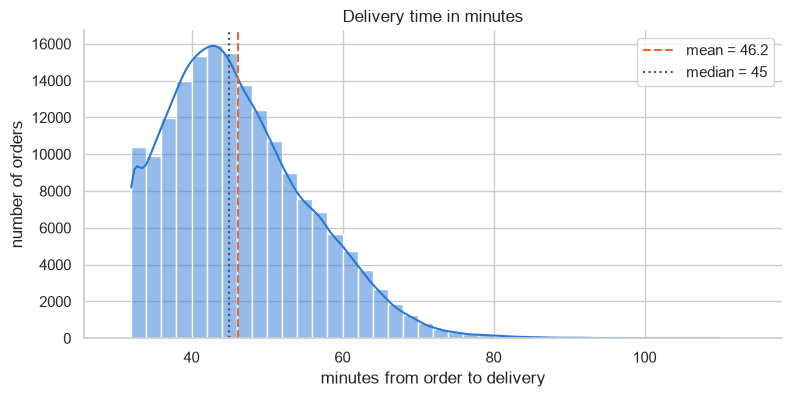

In [28]:
plt.figure(figsize=(9, 4))
sns.histplot(df["time_taken_mins"], bins=range(30, 115, 2), kde=True, color=BLUE)
plt.axvline(df["time_taken_mins"].mean(), color=ORANGE, linestyle="--", linewidth=1.5, label=f"mean = {df['time_taken_mins'].mean():.1f}")
plt.axvline(df["time_taken_mins"].median(), color="#52514e", linestyle=":", linewidth=1.5, label=f"median = {df['time_taken_mins'].median():.0f}")
plt.title("Delivery time in minutes")
plt.xlabel("minutes from order to delivery")
plt.ylabel("number of orders")
plt.legend()
plt.show()

From the output above, delivery time runs from 32 to 110 minutes, with a mean of 46.2 and a median of 45. The mean is above the median and the longest delivery is far above the quartiles (39 and 52), so the distribution is stretched to the right: most deliveries take 39 to 52 minutes and a few take much longer.

## 2.3 Hour of the Day and Day of the Week (Task 2.3)

The `.dt` accessor pulls the hour and the weekday out of the order time. Monday is 0 and Sunday is 6.

In [29]:
df["hour"] = df["created_at"].dt.hour
df["day_of_week"] = df["created_at"].dt.day_of_week

df[["created_at", "hour", "day_of_week"]].head()

,created_at,hour,day_of_week
0,2015-02-06 22:24:17,22,4
1,2015-02-10 21:49:25,21,1
2,2015-02-16 00:11:35,0,0
3,2015-02-12 03:36:46,3,3
4,2015-01-27 02:12:36,2,1


## 2.4 Drop Columns That Are No Longer Needed (Task 2.4)

- `created_at` is now represented by `hour` and `day_of_week`.
- `actual_delivery_time` is the source of the target, so keeping it would give the answer to the model (data leakage).
- `estimated_store_to_consumer_driving_duration` is in the file, but it is not part of the data dictionary of the problem brief. We follow the brief and use only the columns it describes.

In [30]:
df = df.drop(columns=["created_at", "actual_delivery_time", "estimated_store_to_consumer_driving_duration"])

df.columns.tolist()

['market_id',
 'store_primary_category',
 'order_protocol',
 'total_items',
 'subtotal',
 'num_distinct_items',
 'min_item_price',
 'max_item_price',
 'total_onshift_dashers',
 'total_busy_dashers',
 'total_outstanding_orders',
 'time_taken_mins',
 'hour',
 'day_of_week']

## 2.5 Data Cleaning and Null Values (Task 2.5)

### Data Cleaning: Impossible Values

In Section 1 we found values that cannot be real: negative prices, negative partner counts, a zero subtotal, and a cheapest item that costs more than the costliest. First we count how many rows break each rule.

In [31]:
rules = {
    "min_item_price < 0": df["min_item_price"] < 0,
    "total_onshift_dashers < 0": df["total_onshift_dashers"] < 0,
    "total_busy_dashers < 0": df["total_busy_dashers"] < 0,
    "total_outstanding_orders < 0": df["total_outstanding_orders"] < 0,
    "subtotal == 0": df["subtotal"] == 0,
    "min_item_price > max_item_price": df["min_item_price"] > df["max_item_price"],
}

rule_counts = pd.Series({name: int(mask.sum()) for name, mask in rules.items()})
rule_counts

min_item_price < 0                  12
total_onshift_dashers < 0           21
total_busy_dashers < 0              21
total_outstanding_orders < 0        41
subtotal == 0                      161
min_item_price > max_item_price    701
dtype: int64

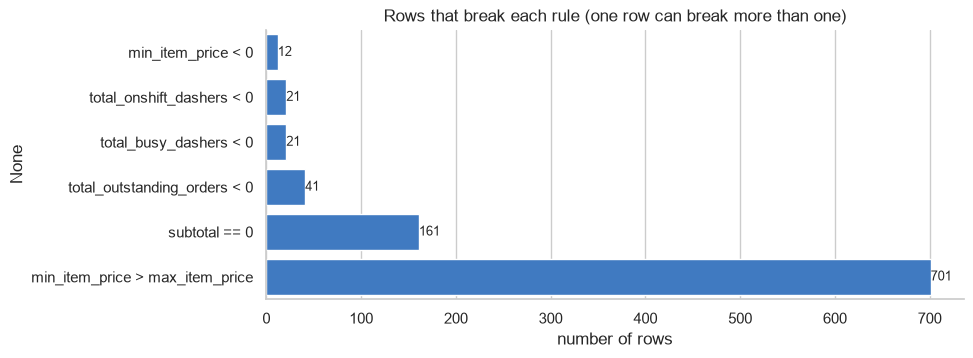

In [32]:
plt.figure(figsize=(9, 3.5))
ax = sns.barplot(x=rule_counts.values, y=rule_counts.index, color=BLUE)
ax.bar_label(ax.containers[0], fmt="{:,.0f}", fontsize=9)
plt.title("Rows that break each rule (one row can break more than one)")
plt.xlabel("number of rows")
plt.show()

These rows are a tiny share of the data, so we remove them. `pd.concat(...).any(axis=1)` marks a row if it breaks at least one rule.

The rows where busy partners exceed on-duty partners are **not** removed. There are far too many of them to be mistakes (Section 1.3).

In [33]:
bad_rows = pd.concat(rules.values(), axis=1).any(axis=1)
print("Rows removed:", bad_rows.sum(), f"({bad_rows.mean() * 100:.2f}% of the data)")

df = df[~bad_rows].reset_index(drop=True)
print("Shape after cleaning:", df.shape)

Rows removed: 940 (0.53% of the data)
Shape after cleaning: (174837, 14)


From the output above, 940 rows (0.53%) broke at least one rule and were removed, which leaves 174,837 rows. The most common problem was a cheapest item that costs more than the costliest (701 rows), followed by a zero subtotal (161 rows).

### Null Values

`df.isnull().sum()` counts the null values in every column. If only a tiny share of rows had nulls we would drop them, and otherwise we would fill them (for example with the median).

In [34]:
print("Total null values:", int(df.isnull().sum().sum()))
df.isnull().sum()

Total null values: 0


market_id                   0
store_primary_category      0
order_protocol              0
total_items                 0
subtotal                    0
num_distinct_items          0
min_item_price              0
max_item_price              0
total_onshift_dashers       0
total_busy_dashers          0
total_outstanding_orders    0
time_taken_mins             0
hour                        0
day_of_week                 0
dtype: int64

From the output above, there are no null values in any column, so nothing had to be dropped or filled. Cleaning the impossible values and creating the target did not create any new nulls.

## 2.6 Encoding the Categorical Column (Task 2.6)

`store_primary_category` has 73 different values. As in the problem brief, we convert the column to the `category` type and take its integer codes. `market_id` and `order_protocol` are stored as decimals (`1.0`, `2.0`), so we convert them to integers.

In [35]:
df["store_category_code"] = df["store_primary_category"].astype("category").cat.codes
df["market_id"] = df["market_id"].astype(int)
df["order_protocol"] = df["order_protocol"].astype(int)

df[["store_primary_category", "store_category_code"]].drop_duplicates().sort_values("store_category_code").head()

,store_primary_category,store_category_code
11940,0,0
32798,1,1
4062,2,2
133349,3,3
0,4,4


In [36]:
df = df.drop(columns=["store_primary_category"])

df.head()

,market_id,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,time_taken_mins,hour,day_of_week,store_category_code
0,1,1,4,3441,4,557,1239,33.0,14.0,21.0,47.0,22,4,4
1,2,2,1,1900,1,1400,1400,1.0,2.0,2.0,44.0,21,1,46
2,2,3,4,4771,3,820,1604,8.0,6.0,18.0,55.0,0,0,36
3,1,1,1,1525,1,1525,1525,5.0,6.0,8.0,59.0,3,3,38
4,1,1,2,3620,2,1425,2195,5.0,5.0,7.0,46.0,2,1,38


**Note:** `market_id` and `order_protocol` are also labels, so we turn them into one-hot columns (`pd.get_dummies`) just before modelling in Section 4. That keeps the original columns available for the charts in Section 3.

In [37]:
print("Shape after Section 2:", df.shape)
df.dtypes

Shape after Section 2: (174837, 14)


market_id                     int64
order_protocol                int64
total_items                   int64
subtotal                      int64
num_distinct_items            int64
min_item_price                int64
max_item_price                int64
total_onshift_dashers       float64
total_busy_dashers          float64
total_outstanding_orders    float64
time_taken_mins             float64
hour                          int32
day_of_week                   int32
store_category_code            int8
dtype: object

From the output above, `store_category_code` now holds an integer code for every restaurant category (in this file the code happens to equal the original category number), and `market_id` and `order_protocol` are integers. The table has 174,837 rows and 14 columns, and every column is numeric.

**Note:** These codes are labels, not amounts: category 40 is not "more" than category 4. A Random Forest copes with this because it only compares thresholds, but a neural network reads the code as a number. This is a limitation of the encoding the brief asks for.

## Section 2 Summary: Objective and How It Was Addressed

**Motto of this section:** *Turn raw records into a clean, numeric table the models can learn from.*

| Task | Where it is addressed | Result |
|:--|:--|:--|
| **Task 2.1:** convert both timestamps to datetime | **2.1**: `pd.to_datetime`, checked with `df.info()` | Both columns are `datetime64[us]` |
| **Task 2.2:** target in minutes | **2.2**: subtract the columns, `.dt.total_seconds() / 60` | `time_taken_mins`: 32 to 110 minutes, mean 46.2 |
| **Task 2.3:** hour of day and day of week | **2.3**: `.dt.hour` and `.dt.day_of_week` | `hour` (0 to 23) and `day_of_week` (Monday = 0) |
| **Task 2.4:** drop columns no longer needed | **2.4**: dropped `created_at`, `actual_delivery_time` (the target's source, so it would leak) and `estimated_store_to_consumer_driving_duration` | 14 columns left |
| **Task 2.5:** nulls and cleaning | **2.5**: six rules for impossible values, then `isnull().sum()` | 940 rows (0.53%) removed; no nulls |
| **Task 2.6:** encode the categorical column | **2.6**: `astype("category").cat.codes` | `store_category_code`; 174,837 rows and 14 columns, all numeric |

**Two decisions to remember:**
- Rows where busy partners exceed on-shift partners (39,290 rows in Section 1) were **kept**. There are far too many of them to be typing mistakes.
- `estimated_store_to_consumer_driving_duration` was **not used**, because the brief's data dictionary does not list it. In the raw file it correlates about 0.46 with delivery time (profiled before this notebook was built), so leaving it out probably costs some accuracy. We did not test that here.

<a id="sec3"></a>

# Section 3: Data Visualization, Outlier Detection and Cleaning (20 points)

### Objective and Tasks of this Section

**Stage 3 of 5 · 6 Tasks: Data Visualization, Outlier Detection & Cleaning**

**Objective:** You will visualize relationships in the cleaned data, understand why outliers matter, detect and remove them, and confirm visually that the cleaning improved the data.

| Task | What to do | Hint |
|:--|:--|:--|
| **Task 3.1** | Visualize relationships between the target and key features — for example a correlation heatmap and scatterplots of time_taken_mins against subtotal, and total_items against subtotal. | Think about which plot type best shows the correlation strength between many numeric columns at once, versus which best shows the relationship between two specific variables. |
| **Task 3.2** | Explain why it's important to check for outliers before training a model on this data. | Think about how a small number of extreme delivery times could disproportionately pull a regression model's error metric or its learned relationships. |
| **Task 3.3** | Name three methods that can be used to detect or remove outliers. | Think about a simple statistical rule based on quartiles, a plot-based visual method, and a model-based method that scores each point relative to its neighbors. |
| **Task 3.4** | Apply an outlier detection method to the data, print how many rows were flagged, and remove those rows. | Think about a method that can flag unusual rows across several columns at once, rather than looking at just one column in isolation. |
| **Task 3.5** | Re-plot the same scatterplot from Task 3.1 after removing outliers, and compare it to the original to confirm the cleaning helped. | Think about which exact plot you produced before cleaning — reusing it after cleaning is the only way to see whether the distribution actually improved. |
| **Task 3.6** | Visualize order volume by day of week and hour of day, and check whether time of day affects delivery time. | Think about which plot best shows a count/frequency by category, versus which best shows a trend across a continuous-like feature such as hour. |

**Evaluation criteria of this section (20 points):**

| Criterion | Done in |
|:--|:--|
| Visualization for various features | 3.1, 3.6 |
| Check for outliers | 3.1 to 3.3 |
| Remove outliers | 3.4 |
| Compare plots and results | 3.5 |

Each task below is marked in its heading, for example `(Task 3.1)`.

---


Now that the data is clean and complete, we look at it with charts (countplots and scatterplots, as in the brief), check for outliers, remove them, and plot the data again to see whether anything improved.

**Flow of this section:**

```
Countplots & scatterplots --> Why outliers matter --> Three methods --> Detect & remove --> Compare --> Day & hour patterns
```

## 3.1 Visualising the Data (Task 3.1)

We import `IsolationForest`, which we use in Section 3.4, and list the eight numeric columns that describe the order and the partner supply.

In [38]:
from sklearn.ensemble import IsolationForest

num_cols = ["total_items", "subtotal", "num_distinct_items", "min_item_price", "max_item_price",
            "total_onshift_dashers", "total_busy_dashers", "total_outstanding_orders"]

day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

### Countplots of the Categorical Columns

A countplot shows how many orders fall into each category.

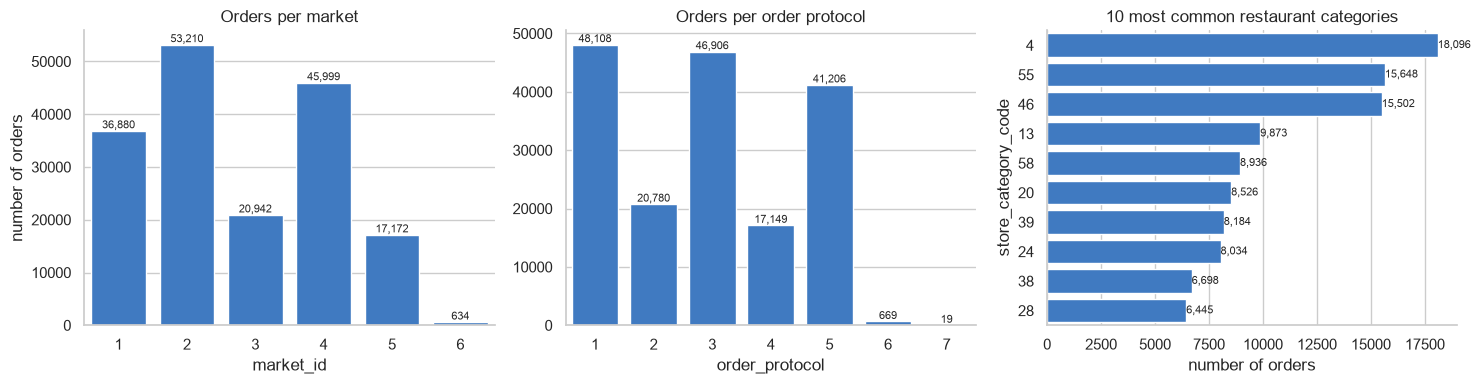

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(data=df, x="market_id", color=BLUE, ax=axes[0])
axes[0].bar_label(axes[0].containers[0], fmt="{:,.0f}", fontsize=8)
axes[0].set_title("Orders per market")
axes[0].set_ylabel("number of orders")

sns.countplot(data=df, x="order_protocol", color=BLUE, ax=axes[1])
axes[1].bar_label(axes[1].containers[0], fmt="{:,.0f}", fontsize=8)
axes[1].set_title("Orders per order protocol")
axes[1].set_ylabel("")

top_codes = df["store_category_code"].value_counts().head(10).index
sns.countplot(data=df, y="store_category_code", order=top_codes, color=BLUE, ax=axes[2])
axes[2].bar_label(axes[2].containers[0], fmt="{:,.0f}", fontsize=8)
axes[2].set_title("10 most common restaurant categories")
axes[2].set_xlabel("number of orders")

plt.tight_layout()
plt.show()

From the charts, market 2 has the most orders (53,210) and market 6 almost none (634). Order protocols 1, 3 and 5 carry most of the orders, while protocols 6 and 7 are rare (669 and 19 orders). A few restaurant categories (4, 55 and 46) account for far more orders than the rest.

### Histograms of the Numeric Columns

A histogram shows how the values of one column are spread. We use a log scale on the vertical axis so that rare, extreme values stay visible next to the very common small ones.

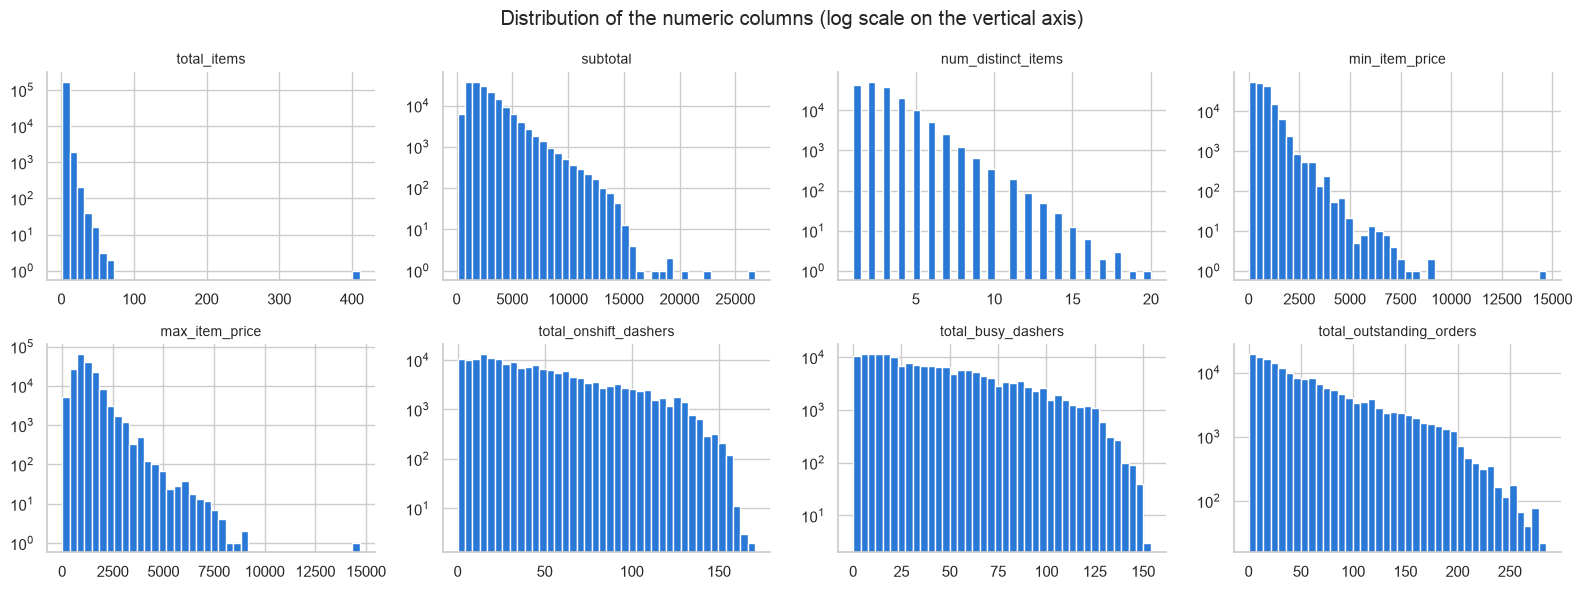

In [40]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.ravel(), num_cols):
    ax.hist(df[col], bins=40, color=BLUE, log=True)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Distribution of the numeric columns (log scale on the vertical axis)")
plt.tight_layout()
plt.show()

From the histograms, every column has most of its values at the low end and a thin tail to the right, and the log scale makes the single rows in those tails visible. `total_items` has almost all orders below about 20 items, yet one order has 411; `subtotal` stretches to 26,800 and the two item-price columns to about 14,700, each with only a handful of rows far out. `num_distinct_items` thins out steadily up to 20. The three partner columns are spread more evenly and only thin out above about 125 to 150, while the number of orders waiting falls off steadily towards 280. This long-tailed shape is why the outlier check in 3.2 to 3.4 matters.

### Correlation Heatmap

`df.corr()` measures how strongly each pair of numeric columns moves together, from -1 to +1. `sns.heatmap` draws it with the numbers printed inside. The colours run from blue (negative) through grey (zero) to orange (positive).

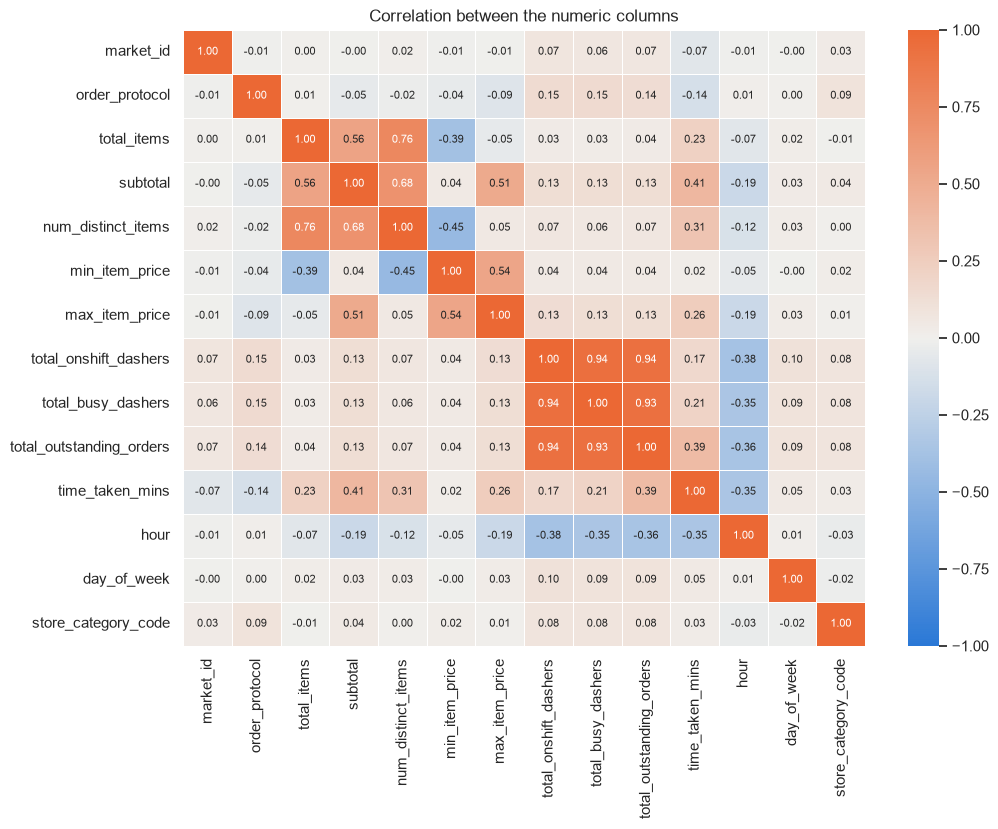

In [41]:
DIVERGING = sns.blend_palette([BLUE, "#f0efec", ORANGE], as_cmap=True)

plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap=DIVERGING, vmin=-1, vmax=1,
            annot_kws={"size": 8}, linewidths=0.5, linecolor="white")
plt.title("Correlation between the numeric columns")
plt.show()

In [42]:
df.corr(numeric_only=True)["time_taken_mins"].sort_values(ascending=False).round(2)

time_taken_mins             1.00
subtotal                    0.41
total_outstanding_orders    0.39
num_distinct_items          0.31
max_item_price              0.26
total_items                 0.23
total_busy_dashers          0.21
total_onshift_dashers       0.17
day_of_week                 0.05
store_category_code         0.03
min_item_price              0.02
market_id                  -0.07
order_protocol             -0.14
hour                       -0.35
Name: time_taken_mins, dtype: float64

From the heatmap, delivery time is most strongly related to `subtotal` (0.41), `total_outstanding_orders` (0.39) and `hour` (-0.35: orders placed at later hours are faster), followed by `num_distinct_items` (0.31). The three supply columns (partners on shift, busy partners, orders waiting) carry almost the same signal, with correlations of 0.93 to 0.94 between them, and `total_items` and `num_distinct_items` also move together (0.76). `store_category_code` (0.03) and `day_of_week` (0.05) show almost no straight-line relation to delivery time, although a model can still use them in other ways.

### Scatterplots (Before Removing Outliers)

We plot delivery time against subtotal, and total items against subtotal. We define the plots as a function, so that exactly the same plot can be drawn again after the outliers are removed. A random sample of 20000 orders keeps the plot readable.

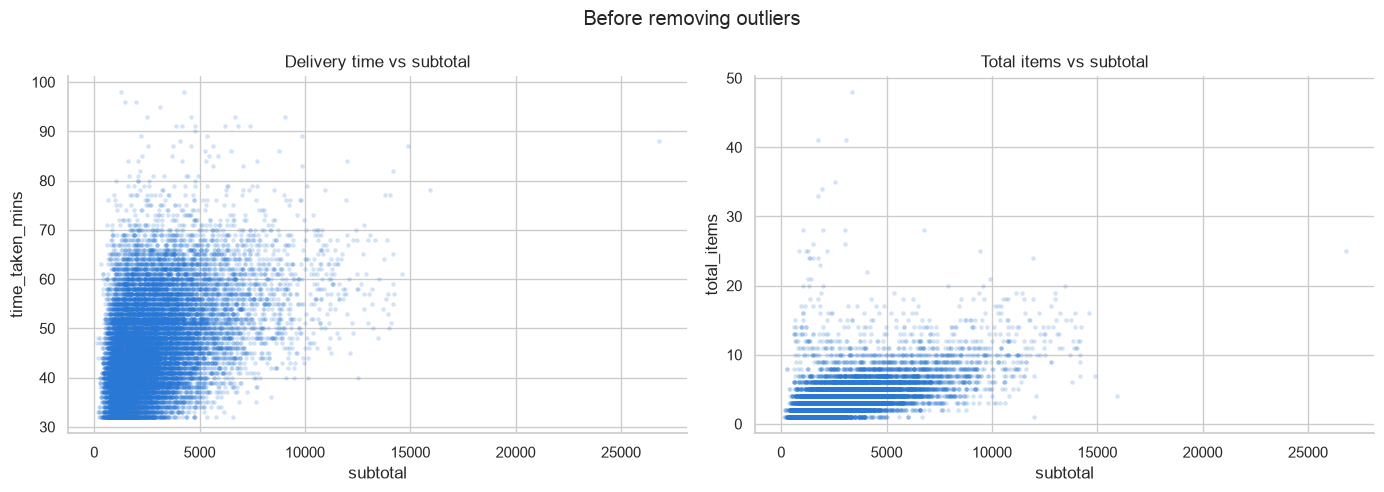

In [43]:
def scatter_pair(data, title):
    sample = data.sample(20000, random_state=42)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.scatterplot(data=sample, x="subtotal", y="time_taken_mins", s=8, alpha=0.2, color=BLUE, edgecolor=None, ax=axes[0])
    axes[0].set_title("Delivery time vs subtotal")
    sns.scatterplot(data=sample, x="subtotal", y="total_items", s=8, alpha=0.2, color=BLUE, edgecolor=None, ax=axes[1])
    axes[1].set_title("Total items vs subtotal")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

scatter_pair(df, "Before removing outliers")

From the scatterplots, delivery time rises with subtotal, but the cloud is wide: orders of the same size take anywhere from 32 to about 100 minutes, so subtotal alone cannot predict delivery time. A few orders sit far to the right (one near 27,000), and in the second plot almost all orders have fewer than 20 items, with a handful of points far above.

### Box Plots to Check for Outliers (Before Removing Outliers)

A box plot shows the middle half of the values as a box and marks the unusual values as dots. Each column has its own scale.

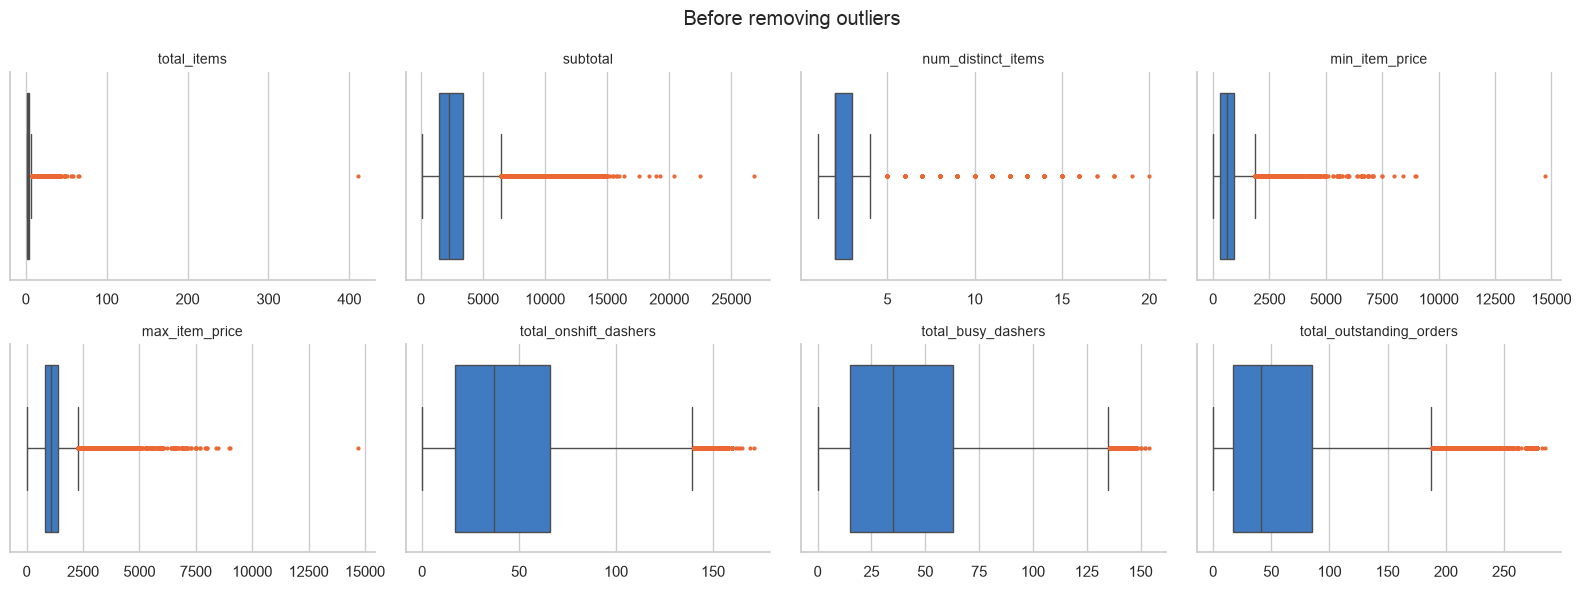

In [44]:
def box_grid(data, title):
    fig, axes = plt.subplots(2, 4, figsize=(16, 6))
    for ax, col in zip(axes.ravel(), num_cols):
        sns.boxplot(x=data[col], color=BLUE, fliersize=2, flierprops={"markerfacecolor": ORANGE, "markeredgecolor": ORANGE}, ax=ax)
        ax.set_title(col, fontsize=10)
        ax.set_xlabel("")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

box_grid(df, "Before removing outliers")

From the box plots, every column has orange dots beyond its whiskers on the right side. `total_items` has one order of 411 items, far away from everything else. `subtotal` and the two item-price columns have long tails of expensive orders, and the three partner columns have dots at the busiest moments. These are the values the rest of this section examines.

## 3.2 Why Check for Outliers? (Task 3.2, Brief Question 4)

> **Brief Question 4:** *Why do we need to check for outliers in our data?*


An **outlier** is a value that sits far away from the rest of the data. We check for them before training because:

- **Averages and spreads get pulled.** One order with 411 items moves the mean and the standard deviation of `total_items`, and `StandardScaler` uses both.
- **Squared errors reward big values.** The mean squared error squares every mistake, so a few extreme rows can dominate the loss and drag the weights of a neural network towards them.
- **Models learn from too little evidence.** A very rare kind of order has so few examples that the model cannot learn it, but it can still distort the rest.
- **They may be mistakes.** Some outliers are typing or system errors that should not be learned at all.

**Note:** An outlier is not automatically wrong. A very large order can be real. So we look at the outliers first, and then decide what to do with them.

## 3.3 Three Methods to Find and Remove Outliers (Task 3.3, Brief Question 5)

> **Brief Question 5:** *Name 3 outlier removal methods?*


| Method | How it works | Looks at |
|:--|:--|:--|
| **IQR rule** (the rule behind a box plot) | A value is an outlier if it is more than 1.5 times the IQR (the width of the middle half) below the first quartile or above the third quartile | One column at a time |
| **Z-score** | A value is an outlier if it is more than 3 standard deviations from the mean | One column at a time |
| **Box plot or scatterplot** (visual method) | Points beyond the whiskers of a box plot, or far away from the main cloud of a scatterplot, are outlier candidates. We drew both in Section 3.1 | One or two columns at a time |
| **Isolation Forest** (also Local Outlier Factor, DBSCAN) | Random trees try to isolate each row. Rows that are isolated with very few splits are unusual | Several columns at once |

The brief allows any method. We use **Isolation Forest** as the main method, because it looks at several columns together instead of one column in isolation. A multi-column method can miss a value that is extreme in only one column, so we add a simple one-column percentile rule after it (Section 3.4).

### How Many Rows Would Each Method Flag?

We apply all three methods to the cleaned data (nothing is removed yet) and count the rows that each one flags. The IQR rule and the z-score flag a row if **any** of the eight numeric columns is extreme. The Isolation Forest looks at the eight columns together.

In [45]:
q1, q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
iqr = q3 - q1
iqr_flag = (df[num_cols] < q1 - 1.5 * iqr) | (df[num_cols] > q3 + 1.5 * iqr)
z_flag = ((df[num_cols] - df[num_cols].mean()) / df[num_cols].std()).abs() > 3
iso_flag = IsolationForest(n_estimators=100, contamination=0.01, random_state=42, n_jobs=-1).fit(df[num_cols]).predict(df[num_cols]) == -1

flag_table = pd.DataFrame({
    "rows flagged": [iqr_flag.any(axis=1).sum(), z_flag.any(axis=1).sum(), iso_flag.sum()],
    "share of the data (%)": [iqr_flag.any(axis=1).mean() * 100, z_flag.any(axis=1).mean() * 100, iso_flag.mean() * 100],
}, index=["IQR rule (any column)", "Z-score above 3 (any column)", "Isolation Forest (eight columns together)"])
flag_table.round(2)

,rows flagged,share of the data (%)
IQR rule (any column),36173,20.69
Z-score above 3 (any column),11222,6.42
Isolation Forest (eight columns together),1749,1.00


From the table, the choice of method changes the number of flagged rows enormously: the IQR rule flags 36,173 rows (20.7% of the data) and the z-score rule flags 11,222 rows (6.4%), while the Isolation Forest flags 1,749 rows (1.0%). The Isolation Forest flags exactly the share we ask for (`contamination=0.01`), whereas the other two decide the number from the data. Almost every column here is skewed to the right, and the IQR rule assumes a more even spread, so it would throw away a fifth of ordinary orders because one column is on the high side. That is why the Isolation Forest is our main method.

## 3.4 Detect and Remove Outliers (Task 3.4)

`contamination=0.01` tells the Isolation Forest to flag about 1% of the rows as the most unusual ones. We give it only the eight numeric input columns and **not** the delivery time, so the target does not decide which rows are removed.

In [46]:
df_before = df.copy()

iso = IsolationForest(n_estimators=100, contamination=0.01, random_state=42, n_jobs=-1)
iso.fit(df[num_cols])
df["is_outlier"] = iso.predict(df[num_cols]) == -1

print("Rows flagged as outliers:", df["is_outlier"].sum(), f"({df['is_outlier'].mean() * 100:.2f}% of the data)")

Rows flagged as outliers: 1749 (1.00% of the data)


The rows the Isolation Forest flagged, so that we can see what it considers unusual (the first ten are printed).

In [47]:
df[df["is_outlier"]][num_cols + ["time_taken_mins"]].head(10)

,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,time_taken_mins
12,7,14900,5,1200,3900,8.0,11.0,11.0,87.0
126,5,8450,5,950,2800,123.0,117.0,190.0,56.0
160,13,9980,10,100,1345,62.0,58.0,102.0,64.0
316,25,10286,14,280,495,41.0,34.0,40.0,53.0
512,7,9800,6,1200,2300,102.0,124.0,132.0,55.0
908,8,11600,7,500,3700,54.0,41.0,51.0,50.0
917,1,7475,1,7475,7475,15.0,14.0,14.0,54.0
1003,3,14700,3,3600,3600,38.0,37.0,38.0,56.0
1020,8,8860,8,795,995,136.0,81.0,137.0,49.0
1202,1,4592,1,4362,4509,18.0,17.0,10.0,38.0


Let's see what the flagged rows look like. In the charts they are drawn in orange.

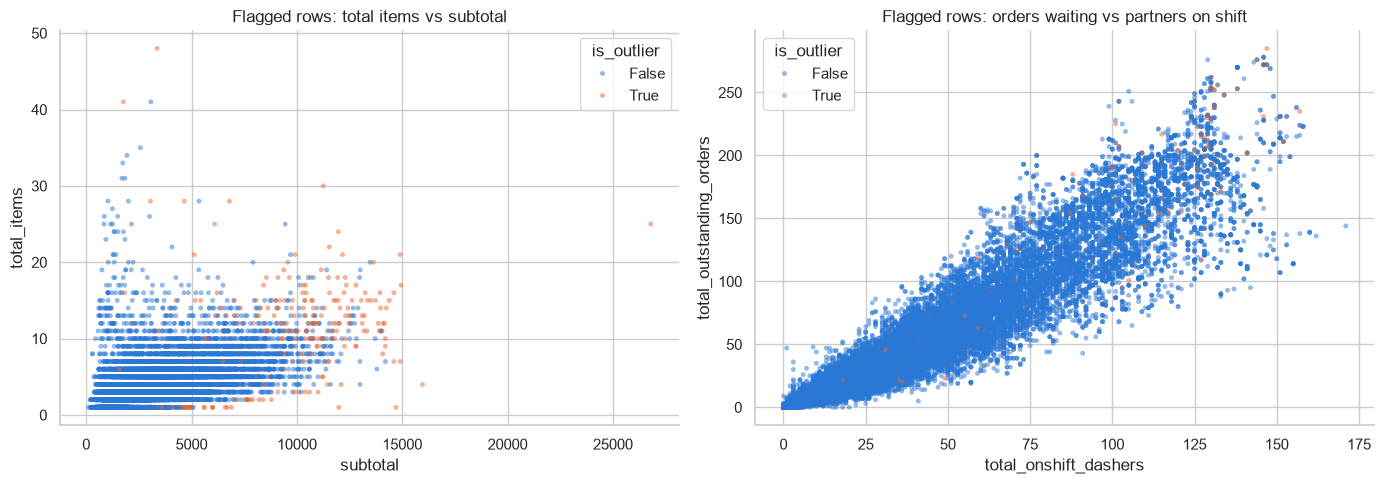

In [48]:
sample = df.sample(30000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=sample, x="subtotal", y="total_items", hue="is_outlier", palette={False: BLUE, True: ORANGE},
                s=10, alpha=0.5, edgecolor=None, ax=axes[0])
axes[0].set_title("Flagged rows: total items vs subtotal")
sns.scatterplot(data=sample, x="total_onshift_dashers", y="total_outstanding_orders", hue="is_outlier", palette={False: BLUE, True: ORANGE},
                s=10, alpha=0.5, edgecolor=None, ax=axes[1])
axes[1].set_title("Flagged rows: orders waiting vs partners on shift")
plt.tight_layout()
plt.show()

In [49]:
df.groupby("is_outlier")[num_cols + ["time_taken_mins"]].mean().T.round(1)

is_outlier,False,True
total_items,3.1,9.8
subtotal,2644.1,8516.6
num_distinct_items,2.6,6.7
min_item_price,677.1,1244.3
max_item_price,1149.3,2220.3
total_onshift_dashers,44.6,74.7
total_busy_dashers,41.6,69.9
total_outstanding_orders,57.7,112.1
time_taken_mins,46.1,60.0


From the output above, the Isolation Forest flagged 1,749 rows (1.00%), and 173,088 rows remain after removing them. The flagged orders are much bigger (average subtotal 8,517 against 2,644, and 9.8 items against 3.1) and were placed at busy moments (112 orders waiting against 58). Their average delivery time is 60 minutes against 46, even though delivery time was **not** given to the method, so the flagged rows are genuinely unusual deliveries and not a random 1%.

Now we remove the flagged rows.

In [50]:
df = df[~df["is_outlier"]].drop(columns="is_outlier").reset_index(drop=True)

print("Rows before:", len(df_before))
print("Rows after :", len(df))

Rows before: 174837
Rows after : 173088


### A Second, Simple Rule for One Extreme Column

The Isolation Forest judges all eight columns together, so an order that is extreme in **one** column but ordinary in the others can slip through. Let's check the largest item counts that are left.

In [51]:
df.sort_values("total_items", ascending=False)[["total_items", "subtotal", "num_distinct_items", "max_item_price", "time_taken_mins"]].head(8)

,total_items,subtotal,num_distinct_items,max_item_price,time_taken_mins
41285,411,3115,5,299,40.0
159933,66,1634,6,499,35.0
159929,64,1166,4,499,32.0
65866,59,2911,3,329,35.0
13092,57,858,5,229,32.0
9685,56,2317,7,289,37.0
92271,51,1343,4,169,43.0
111988,48,3786,7,435,34.0


One order has 411 items, and the next largest has only 66. This order has just 5 different items and a subtotal of about 3,100, which does not fit 411 items, so it is almost certainly a data entry error.

A rule such as the IQR fence (`Q3 + 1.5 x IQR`) would be too harsh here: the middle half of the orders has 2 to 4 items, so the fence is only 7 items and would remove thousands of ordinary larger orders. Instead we remove only the most extreme 0.1%: orders with more items than the **99.9th percentile** of `total_items`.

In [52]:
cap = df["total_items"].quantile(0.999)
extreme = df["total_items"] > cap

print(f"99.9th percentile of total_items: {cap:.1f}")
print(f"Rows above it: {extreme.sum()} ({extreme.mean() * 100:.2f}% of the data)")
print(f"Average delivery time of these rows: {df.loc[extreme, 'time_taken_mins'].mean():.1f} minutes (all rows: {df['time_taken_mins'].mean():.1f})")

df = df[~extreme].reset_index(drop=True)
print("Rows after the second rule:", len(df))

99.9th percentile of total_items: 21.9
Rows above it: 174 (0.10% of the data)
Average delivery time of these rows: 42.7 minutes (all rows: 46.1)
Rows after the second rule: 172914


**Note on the order of the steps:** the brief cleans the data before splitting it, so the outlier rules (including the 99.9th percentile) were worked out on all rows, also on rows that later land in the test set. Only input columns were used, never the target, so the effect is small, but it is a mild form of leakage. In a live system the rules would be fitted on the training rows only and then applied unchanged to new orders.

From the output above, the largest item counts are 411, then 66, 64, 59 and so on: the 411-item order is far away from everything else. The 99.9th percentile of `total_items` is 21.9, and 174 rows (0.10%) are above it, so 172,914 rows remain. These rows are not slower than normal orders (42.7 minutes on average against 46.1 for all rows), so removing them does not throw away the slowest deliveries.

## 3.5 Compare the Plots and Results Before and After (Task 3.5)

We draw exactly the same scatterplots and box plots again and compare them with the earlier ones.

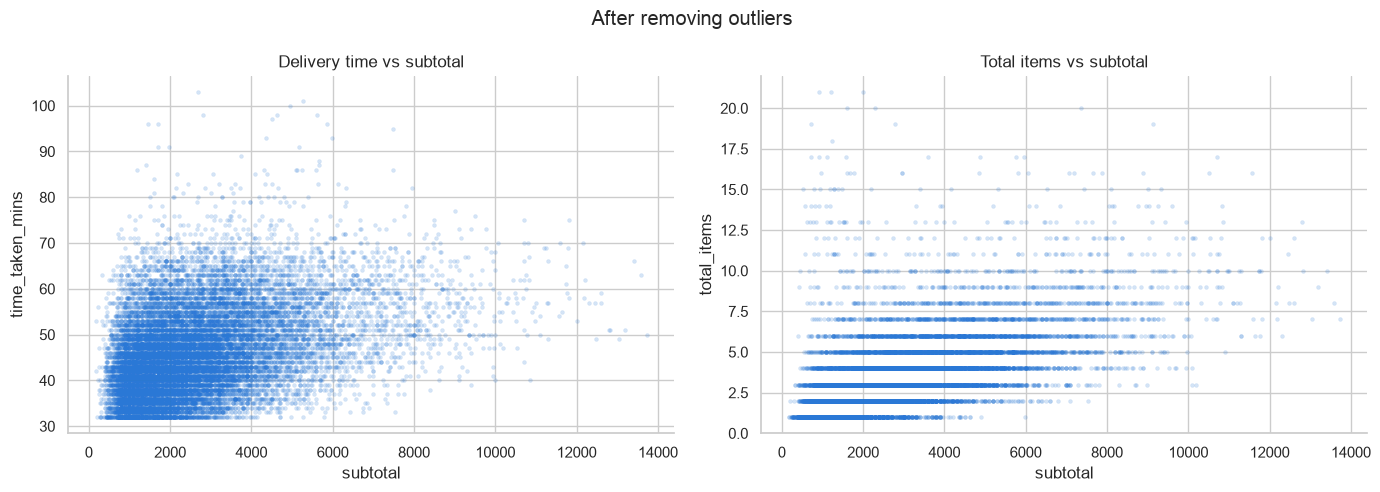

In [53]:
scatter_pair(df, "After removing outliers")

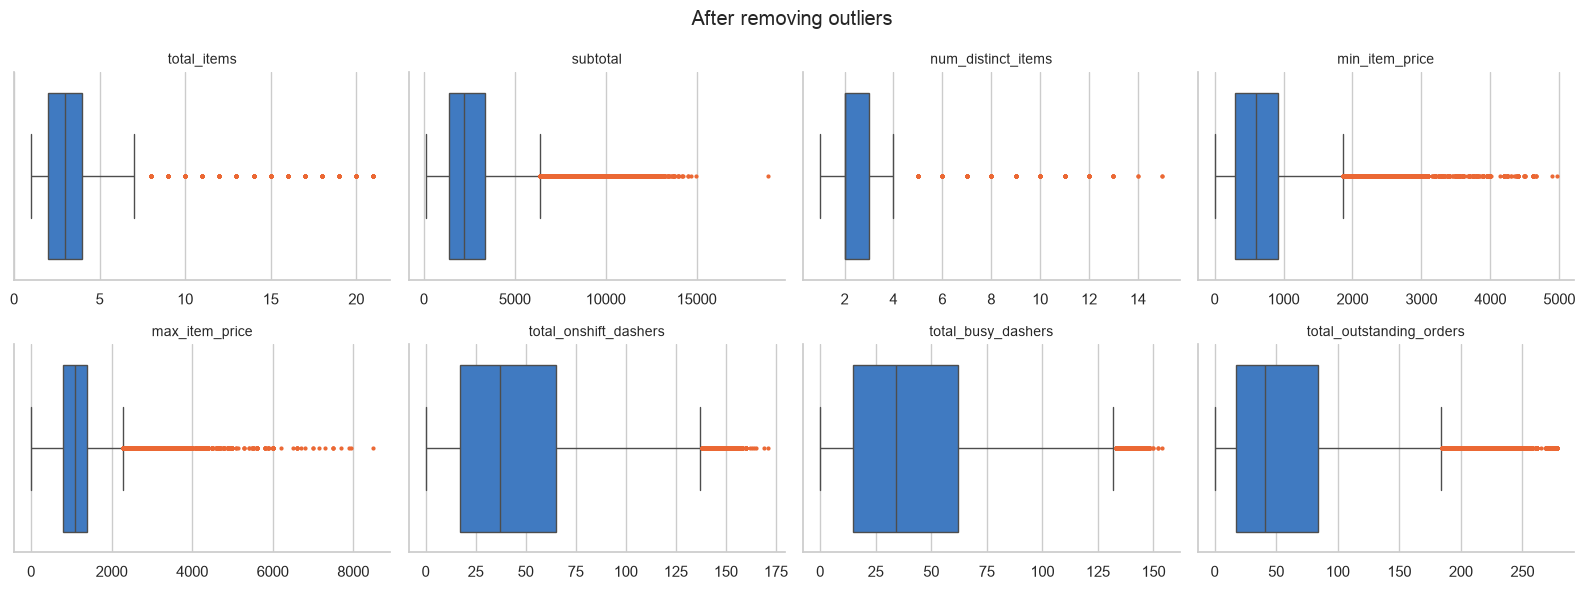

In [54]:
box_grid(df, "After removing outliers")

The numbers tell the same story:

In [55]:
def summary(data):
    return pd.Series({
        "rows": len(data),
        "max total_items": data["total_items"].max(),
        "max subtotal": data["subtotal"].max(),
        "max total_outstanding_orders": data["total_outstanding_orders"].max(),
        "std of subtotal": data["subtotal"].std(),
        "std of delivery time": data["time_taken_mins"].std(),
        "corr(time, subtotal)": data["time_taken_mins"].corr(data["subtotal"]),
    })

pd.DataFrame({"before": summary(df_before), "after": summary(df)}).round(2)

,before,after
rows,174837.00,172914.00
max total_items,411.00,21.00
max subtotal,26800.00,18920.00
max total_outstanding_orders,285.00,278.00
std of subtotal,1829.61,1703.35
std of delivery time,9.33,9.23
"corr(time, subtotal)",0.41,0.40


From the output above, after both steps 172,914 rows remain: 1,923 fewer than before (1,749 from the Isolation Forest and 174 from the percentile rule), which is 1.1% of the data. The largest subtotal fell from 26,800 to 18,920, the largest item count from 411 to 21 and the largest number of waiting orders from 285 to 278. The spread of subtotal fell from 1,830 to 1,703 and the spread of delivery time from 9.33 to 9.23, and the correlation between delivery time and subtotal barely changed (0.41 to 0.40).

So the cleaning removed the extreme rows and left the main relationships alone: the "after" scatterplot of items against subtotal is no longer stretched by a single 411-item order, and the cloud of delivery time against subtotal keeps its shape.

## 3.6 Order Volume and Delivery Time by Day and Hour (Task 3.6)

Does the time of the order change how long delivery takes? The charts on the left count the orders, and the charts on the right show the average delivery time with its 95% confidence band.

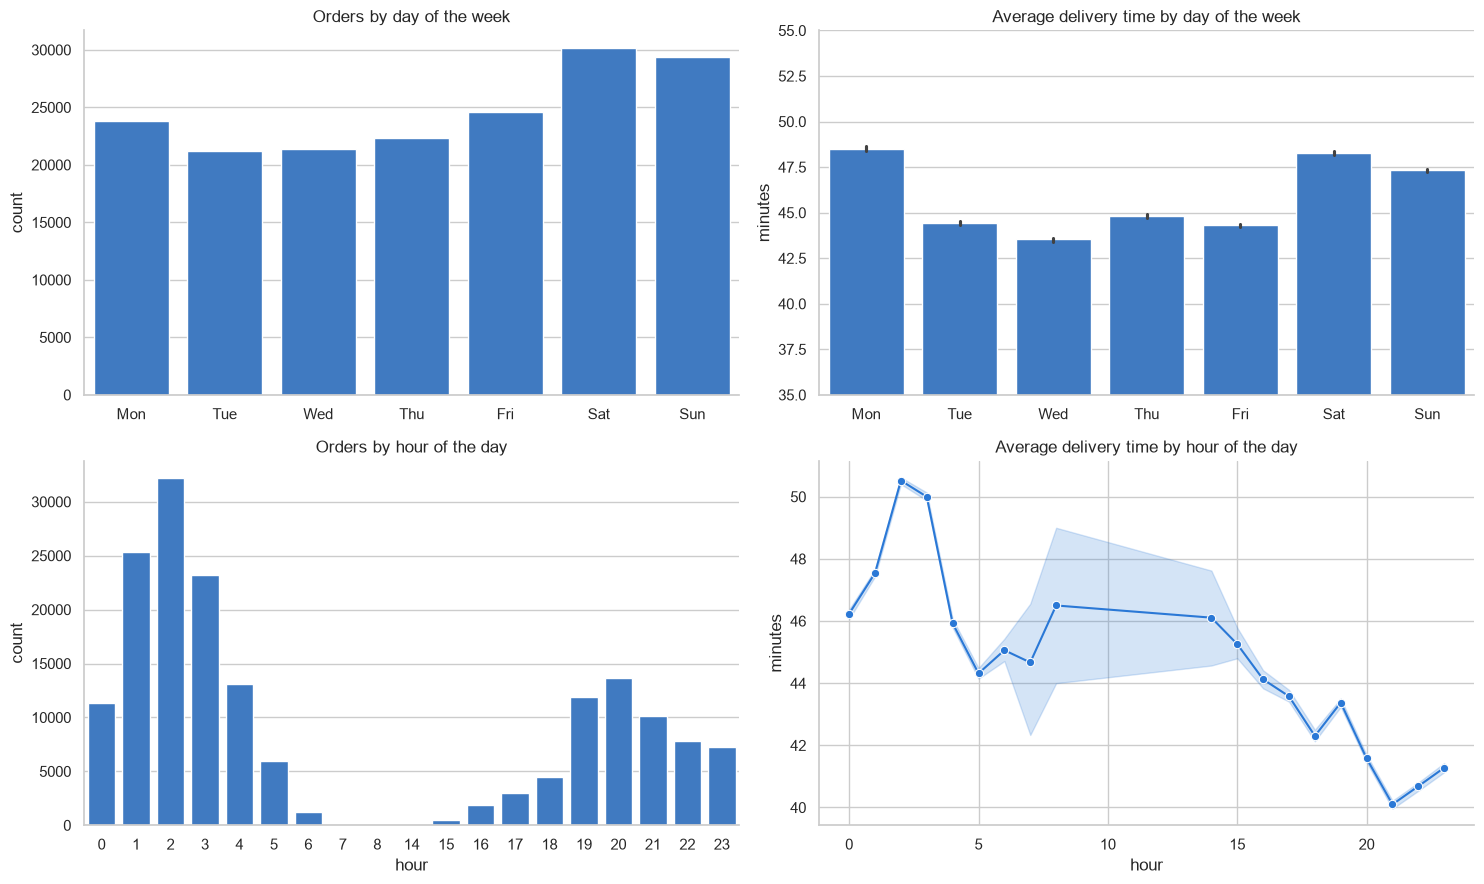

In [56]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

sns.countplot(data=df, x="day_of_week", color=BLUE, ax=axes[0, 0])
axes[0, 0].set_xticks(range(7))
axes[0, 0].set_xticklabels(day_names)
axes[0, 0].set_title("Orders by day of the week")
axes[0, 0].set_xlabel("")

sns.barplot(data=df, x="day_of_week", y="time_taken_mins", color=BLUE, errorbar=("ci", 95), n_boot=200, ax=axes[0, 1])
axes[0, 1].set_xticks(range(7))
axes[0, 1].set_xticklabels(day_names)
axes[0, 1].set_ylim(35, 55)
axes[0, 1].set_title("Average delivery time by day of the week")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("minutes")

sns.countplot(data=df, x="hour", color=BLUE, ax=axes[1, 0])
axes[1, 0].set_title("Orders by hour of the day")

sns.lineplot(data=df, x="hour", y="time_taken_mins", marker="o", color=BLUE, errorbar=("ci", 95), n_boot=200, ax=axes[1, 1])
axes[1, 1].set_title("Average delivery time by hour of the day")
axes[1, 1].set_ylabel("minutes")

plt.tight_layout()
plt.show()

In [57]:
print("Average delivery time by hour (minutes):")
print(df.groupby("hour")["time_taken_mins"].mean().round(1).to_string())
print("\nAverage delivery time by day of the week (minutes):")
print(df.groupby("day_of_week")["time_taken_mins"].mean().round(1).rename(dict(enumerate(day_names))).to_string())

Average delivery time by hour (minutes):
hour
0     46.2
1     47.5
2     50.5
3     50.0
4     45.9
5     44.3
6     45.1
7     44.7
8     46.5
14    46.1
15    45.3
16    44.1
17    43.6
18    42.3
19    43.4
20    41.6
21    40.1
22    40.7
23    41.3

Average delivery time by day of the week (minutes):
day_of_week
Mon    48.5
Tue    44.4
Wed    43.5
Thu    44.8
Fri    44.3
Sat    48.3
Sun    47.3


From the charts, orders are not spread evenly over the day. Almost all orders are placed between hours 0 and 4 and between hours 19 and 23 (as recorded in the file), and hours 6 to 15 have very few orders (hours 9 to 13 have none), which is why the line for those hours has a wide band. Delivery takes longest for orders placed at hours 2 and 3 (about 50 minutes) and shortest at hour 21 (40.1 minutes), a difference of about 10 minutes.

Saturdays and Sundays have the most orders (about 30,000 each), and Mondays (48.5 minutes) and Saturdays (48.3) are the slowest days, while Wednesdays (43.5) are the fastest. So the time of the order does affect delivery time, and `hour` and `day_of_week` are worth keeping as features.

## Section 3 Summary: Objective and How It Was Addressed

**Motto of this section:** *Look at the data, find what does not belong, and check that removing it helped.*

| Task | Where it is addressed | Result |
|:--|:--|:--|
| **Task 3.1:** correlation heatmap and scatterplots | **3.1**: countplots, histograms, correlation heatmap, scatterplots (time vs subtotal, items vs subtotal), box plots | Delivery time relates most to subtotal (0.41), orders waiting (0.39) and hour (-0.35) |
| **Task 3.2 and Question 4:** why check for outliers | **3.2** | Extreme values pull averages, scalers and squared errors |
| **Task 3.3 and Question 5:** three methods | **3.3**: IQR rule, z-score, Isolation Forest, the visual box plot and scatterplot, and a table of how many rows each would flag | IQR would flag 20.7% of rows, z-score 6.4%, Isolation Forest 1.0%; Isolation Forest chosen |
| **Task 3.4:** detect, print and remove | **3.4**: Isolation Forest on eight numeric columns (1,749 rows), then a 99.9th-percentile rule on `total_items` (174 rows) | 172,914 rows left (1.1% removed) |
| **Task 3.5:** re-plot and compare | **3.5**: same scatterplots and box plots, before and after, plus a table | Largest items 411 to 21, largest subtotal 26,800 to 18,920 |
| **Task 3.6:** volume and delivery time by day and hour | **3.6**: countplots and line plots with 95% bands | Orders cluster at hours 0 to 4 and 19 to 23; delivery is slowest at hours 2 to 3 and fastest at hour 21 |

**Limitation to remember:** the outlier rules were worked out on all rows before the split, so they saw rows that later became test rows (only input columns were used, never the target).

<a id="sec4"></a>

# Section 4: Model Training with Random Forest (10 points)

### Objective and Tasks of this Section

**Stage 4 of 5 · 4 Tasks: Baseline Model with Random Forest**

**Objective:** You will split the cleaned data into train and test sets, train a random forest baseline, and evaluate it thoroughly so it can act as a benchmark for the neural network.

| Task | What to do | Hint |
|:--|:--|:--|
| **Task 4.1** | Split the cleaned, encoded data into training and test sets in a reproducible way. | Think about which train_test_split parameter controls the proportion held out for testing, and which one makes the split reproducible across runs. |
| **Task 4.2** | Train a random forest regression model as your baseline. | Think about which scikit-learn class implements an ensemble of decision trees for a regression target. |
| **Task 4.3** | Evaluate the random forest on the test set using multiple error metrics, and identify which features matter most. | Think about why reporting more than one error metric (magnitude in the same unit as the target, plus a normalized/percentage view) gives a fuller picture than a single number. |
| **Task 4.4** | Name other classical machine learning methods (besides random forest) that could be used for this regression problem. | Think about other regression algorithms you know that don't rely on neural networks — both linear and tree/ensemble-based. |

**Evaluation criteria of this section (10 points):**

| Criterion | Done in |
|:--|:--|
| Data splitting | 4.1 |
| Random forest regression | 4.2, 4.3 |

Each task below is marked in its heading, for example `(Task 4.1)`.

---


Before building a neural network we need a baseline: a strong, simple model whose numbers the neural network must beat. As in the brief, we split the data into train and test sets, train a Random Forest, and check its MSE, RMSE and MAE.

**Flow of this section:**

```
Encode & split --> Random Forest --> Metrics --> Other classical methods
```

## 4.1 Preparing the Features and Splitting the Data (Task 4.1)

`market_id` and `order_protocol` are labels, so we turn them into one-hot columns with `pd.get_dummies(..., dtype=float)`. `store_category_code` keeps its integer codes. Then `X` holds the inputs and `y` the target.

In [58]:
X = pd.get_dummies(df.drop(columns=["time_taken_mins"]), columns=["market_id", "order_protocol"], dtype=float)
y = df["time_taken_mins"]

print(X.shape, y.shape)
X.head()

(172914, 24) (172914,)


,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,hour,day_of_week,...,market_id_4,market_id_5,market_id_6,order_protocol_1,order_protocol_2,order_protocol_3,order_protocol_4,order_protocol_5,order_protocol_6,order_protocol_7
0,4,3441,4,557,1239,33.0,14.0,21.0,22,4,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,1900,1,1400,1400,1.0,2.0,2.0,21,1,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,4,4771,3,820,1604,8.0,6.0,18.0,0,0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,1,1525,1,1525,1525,5.0,6.0,8.0,3,3,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2,3620,2,1425,2195,5.0,5.0,7.0,2,1,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


`train_test_split` keeps 20% of the rows for testing. `random_state=42` makes the split reproducible, so every run gives the same train and test sets. We do not use `stratify`, because the target is a continuous number.

In [59]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train:", X_train.shape, y_train.shape)
print("Test :", X_test.shape, y_test.shape)

Train: (138331, 24) (138331,)
Test : (34583, 24) (34583,)


The test set must look like the training set. Let's check the delivery time in both.

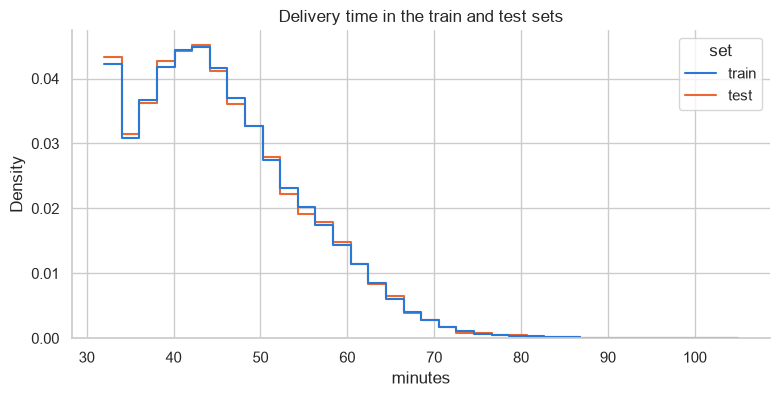

In [60]:
split_target = pd.concat([
    pd.DataFrame({"minutes": y_train, "set": "train"}),
    pd.DataFrame({"minutes": y_test, "set": "test"}),
])

plt.figure(figsize=(9, 4))
sns.histplot(data=split_target, x="minutes", hue="set", binwidth=2, stat="density", common_norm=False,
             element="step", fill=False, palette=[BLUE, ORANGE])
plt.title("Delivery time in the train and test sets")
plt.show()

From the output above, the split gives 138,331 training rows and 34,583 test rows, each with 24 feature columns. In the histogram the delivery-time curves of the two sets lie almost on top of each other, so the test set is a fair sample of the same kind of orders.

## 4.2 Random Forest Regression (Task 4.2)

`RandomForestRegressor` builds many decision trees on random parts of the data and averages their predictions. We use 100 trees, `n_jobs=-1` to use all processor cores, and a fixed `random_state`.

**Note:** A Random Forest splits on thresholds, so it does not need scaled features (see Section 5.1).

In [61]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

## 4.3 Evaluate the Random Forest and Find the Important Features (Task 4.3)

We report MSE, RMSE and MAE, as in the brief. We also report two normalised views: R² (the share of the variation in delivery time that the model explains, which tells us how accurate the model is) and MAPE (the average error as a percentage of the true delivery time). MAE is the average miss in minutes, RMSE is also in minutes but punishes big misses more, and MSE is the quantity a neural network minimises. The training scores next to the test scores show whether the forest has memorised the training data.

In [62]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def regression_report(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    mape = float(np.mean(np.abs((np.asarray(y_true) - y_pred) / np.asarray(y_true))) * 100)
    return dict(MSE=mse, RMSE=mse ** 0.5, MAE=mean_absolute_error(y_true, y_pred), R2=r2_score(y_true, y_pred), MAPE_percent=mape)

rf_train_pred = rf.predict(X_train)
rf_test_pred = rf.predict(X_test)

rf_train_res = regression_report(y_train, rf_train_pred)
rf_test_res = regression_report(y_test, rf_test_pred)

pd.DataFrame({"Random Forest (train)": rf_train_res, "Random Forest (test)": rf_test_res}).round(3)

,Random Forest (train),Random Forest (test)
MSE,3.109,22.015
RMSE,1.763,4.692
MAE,1.368,3.678
R2,0.963,0.744
MAPE_percent,3.017,8.135


Two charts show where the Random Forest is right and wrong. On the left, each dot is an order: a perfect model would put every dot on the dashed diagonal. On the right is the distribution of the errors (actual minus predicted).

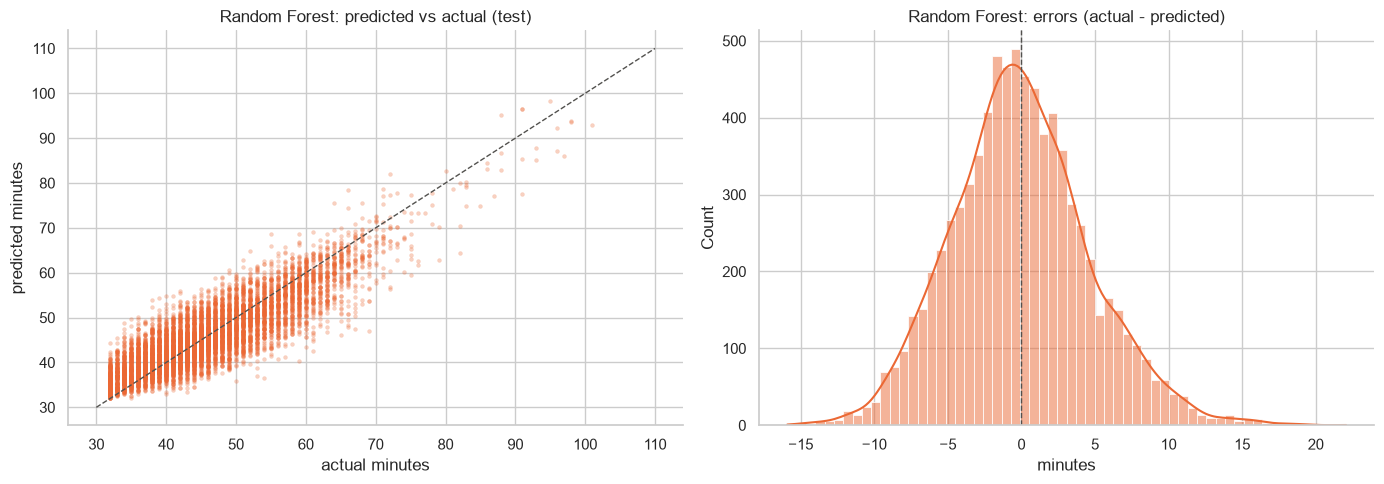

In [63]:
test_sample = pd.DataFrame({"actual": y_test.values, "predicted": rf_test_pred}).sample(8000, random_state=42)
test_sample["error"] = test_sample["actual"] - test_sample["predicted"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=test_sample, x="actual", y="predicted", s=8, alpha=0.3, color=ORANGE, edgecolor=None, ax=axes[0])
axes[0].plot([30, 110], [30, 110], color="#52514e", linestyle="--", linewidth=1)
axes[0].set_title("Random Forest: predicted vs actual (test)")
axes[0].set_xlabel("actual minutes")
axes[0].set_ylabel("predicted minutes")

sns.histplot(test_sample["error"], bins=60, kde=True, color=ORANGE, ax=axes[1])
axes[1].axvline(0, color="#52514e", linestyle="--", linewidth=1)
axes[1].set_title("Random Forest: errors (actual - predicted)")
axes[1].set_xlabel("minutes")
plt.tight_layout()
plt.show()

From the output above, on the test set the forest is off by 3.68 minutes on average (MAE), its RMSE is 4.69 minutes, its R² is 0.744, and its average error is 8.1% of the true delivery time (MAPE). On the training set the same forest has an RMSE of only 1.76 and an R² of 0.963, so it has partly memorised the training rows. The gap between 1.76 and 4.69 is the price of that overfitting, and the test numbers are the ones to trust.

For scale, a model that always predicts the average delivery time would be off by about 9 minutes (the standard deviation of the target), so the forest removes roughly half of that error. In the chart on the left the forest follows the diagonal, but for slow deliveries (above about 70 minutes) it tends to predict too low.

Which features does the forest rely on most? `feature_importances_` shows how much each feature reduced the error across all the trees.

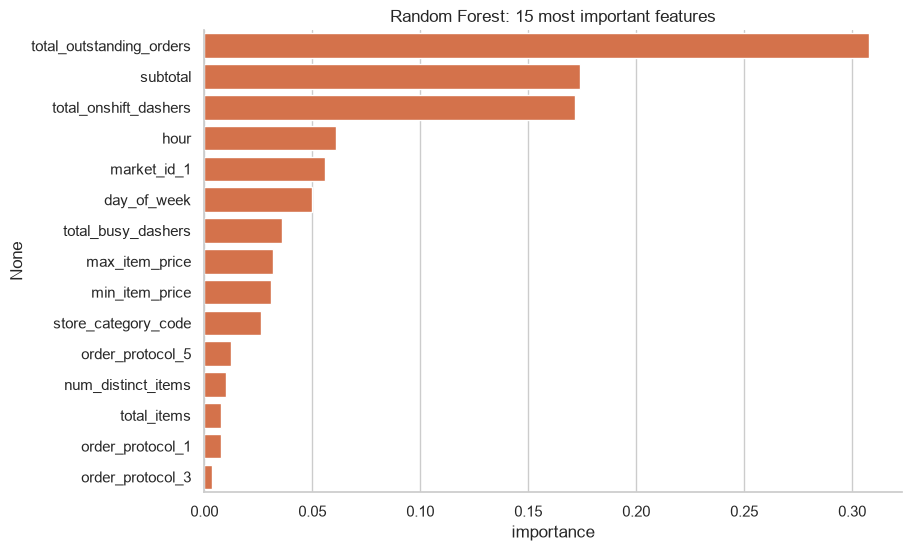

In [64]:
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
sns.barplot(x=importance.values, y=importance.index, color=ORANGE)
plt.title("Random Forest: 15 most important features")
plt.xlabel("importance")
plt.show()

From the chart, the forest relies most on `total_outstanding_orders` (about 0.31), then on `subtotal` and `total_onshift_dashers` (about 0.17 each), followed by `hour`, `market_id_1` and `day_of_week`. The partner columns are strongly correlated with each other (Section 3.1), so the forest splits their importance between them: read the ranking as groups of features, not as exact scores.

## 4.4 Other Classical Methods for Regression (Task 4.4, Brief Question 6)

> **Brief Question 6:** *What classical machine learning methods can we use other than random forest for regression?*


Besides Random Forest, these classical machine learning methods can predict a number:

| Method | Idea |
|:--|:--|
| Linear Regression (and Ridge, Lasso) | A weighted sum of the features, with optional penalties on large weights |
| Decision Tree Regressor | One tree of yes/no splits |
| Gradient Boosting (XGBoost, LightGBM, `GradientBoostingRegressor`) | Many small trees, each correcting the errors of the previous ones |
| K-Nearest Neighbours Regressor | The average of the most similar training orders |
| Support Vector Regression | A kernel method that fits a tube around the data |

### A Quick Test of Some of Them

The brief only asks us to name the methods. Since it takes a minute, we also train three of them on the same training rows and score them on the same test rows, so that the Random Forest result can be put in perspective. These scores are not used to choose anything.

In [65]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

classical = {"Linear Regression": LinearRegression(),
             "Decision Tree (at least 20 rows per leaf)": DecisionTreeRegressor(min_samples_leaf=20, random_state=42),
             "Gradient Boosting (HistGradientBoosting)": HistGradientBoostingRegressor(random_state=42)}

classical_rows = {}
for name, model in classical.items():
    model.fit(X_train, y_train)
    classical_rows[name] = regression_report(y_test, model.predict(X_test))
classical_rows["Random Forest (Section 4.3)"] = rf_test_res

pd.DataFrame(classical_rows).T[["RMSE", "MAE", "R2", "MAPE_percent"]].round(3)

,RMSE,MAE,R2,MAPE_percent
Linear Regression,5.134,4.038,0.693,9.005
Decision Tree (at least 20 rows per leaf),5.195,4.032,0.686,8.883
Gradient Boosting (HistGradientBoosting),4.573,3.602,0.756,7.952
Random Forest (Section 4.3),4.692,3.678,0.744,8.135


From the table, the ensembles are clearly better than the two simple models: Linear Regression (RMSE 5.13) and the single Decision Tree (5.20) are about 0.4 to 0.5 minutes worse than the Random Forest (4.69), and Gradient Boosting is the best of the four (4.57, R² 0.756). So the link between the features and delivery time is not a straight line, and it needs a flexible model. These are test scores for models with default settings, shown for perspective. Section 5.5 compares the neural network (RMSE 4.44) with all of them.

## Section 4 Summary: Objective and How It Was Addressed

**Motto of this section:** *Set a baseline that is strong and honest, so that the neural network has something real to beat.*

| Task | Where it is addressed | Result |
|:--|:--|:--|
| **Task 4.1:** reproducible split | **4.1**: `pd.get_dummies` for `market_id` and `order_protocol`, `train_test_split(test_size=0.2, random_state=42)` | 138,331 train rows, 34,583 test rows, 24 features |
| **Task 4.2:** Random Forest | **4.2**: `RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)` | Trained on the training rows only |
| **Task 4.3:** metrics and important features | **4.3**: MSE, RMSE, MAE, R² and MAPE on train and test, charts, `feature_importances_` | Test RMSE 4.69, MAE 3.68, R² 0.744, MAPE 8.1%; most important: orders waiting, subtotal, partners on shift |
| **Task 4.4 and Question 6:** other classical methods | **4.4**: table of five methods, and a quick test of three | Linear 5.13, Decision Tree 5.20, Gradient Boosting 4.57 (test RMSE) |

**Baseline to beat:** test RMSE **4.69** minutes (train RMSE 1.76, so the forest overfits).

<a id="sec5"></a>

# Section 5: Regression with Neural Networks (30 points)

### Objective and Tasks of this Section

**Stage 5 of 5 · 6 Tasks: Regression with Neural Networks**

**Objective:** You will scale the data, design and train a neural network regressor, check it for overfitting, and compare its performance directly against the random forest baseline.

| Task | What to do | Hint |
|:--|:--|:--|
| **Task 5.1** | Scale the feature data before feeding it into a neural network, and explain why scaling matters here but wasn't required for the random forest. | Think about how a neural network's gradient-based training reacts to features that are on very different numeric ranges, compared to how a tree-based model splits on raw values. |
| **Task 5.2** | Define a neural network architecture appropriate for this regression task, and justify your choice of activation functions. | Think about what activation the output layer needs for a continuous target, versus what activation is a strong general-purpose default for the hidden layers. |
| **Task 5.3** | Compile the model with an optimizer and loss function suited to this regression task, and briefly justify your choice of optimizer. | Think about the drawback of a fixed, single learning rate across all weights, and what an adaptive, per-parameter learning-rate optimizer offers instead. |
| **Task 5.4** | Train the network for a reasonable number of epochs, then plot training vs validation loss to check for overfitting. | Think about what it means for the validation loss to track closely with (or stay below) the training loss over the course of training. |
| **Task 5.5** | Evaluate the trained network on the test set using the same set of metrics used for the random forest, and directly compare the two models' results. | Think about why using the exact same metrics as your baseline is necessary in order to make a fair, direct comparison. |
| **Task 5.6** | Explain why neural networks tend to perform well as dataset size grows. | Think about the relationship between the number of learnable parameters in a network and the amount of data needed to estimate them reliably without overfitting. |

**Evaluation criteria of this section (30 points):**

| Criterion | Done in |
|:--|:--|
| Data scaling | 5.1 |
| Defining nn architecture | 5.2 |
| Trying different combinations and hyperparameters | 5.4 |
| Model training | 5.4 |
| Comparing results with random forest | 5.5 |

Each task below is marked in its heading, for example `(Task 5.1)`.

---


Now we build a neural network in PyTorch, following the structure used in the course: scale the data, build the model, choose the loss and the optimizer, write our own training loop, and try different configurations one at a time. At the end we compare the network with the Random Forest.

**Flow of this section:**

```
Scale --> Architecture --> Loss & optimizer --> Train & plot losses --> Try configurations --> Final model --> Compare with Random Forest
```

## 5.1 Scaling the Data (Task 5.1, Brief Question 7)

> **Brief Question 7:** *Why is scaling required for neural networks?*


Neural networks learn with gradient descent, so the size of the numbers matters. `subtotal` runs into thousands while `hour` is between 0 and 23. Unscaled inputs give a stretched, lopsided loss surface, and gradient descent zig-zags across it. A forest does not care, because it only compares each feature with a threshold.

**Standardisation** (`z = (x - mean) / std`) puts every column on the same footing. We fit the scaler on the **training set only** and just transform the other sets, otherwise information from data the model must never see would leak into training.

We also scale the **target**. A network starts with outputs near 0 while delivery times are around 46, so scaling `y` makes the first steps of training sensible. Predictions are converted back to minutes with `inverse_transform` before we calculate any metric.

To plot the training and validation loss we need a validation set. We set aside 12.5% of the training rows for it, so the network trains on 70% of the data, validates on 10%, and the test set (20%) stays untouched.

In [66]:
from sklearn.preprocessing import StandardScaler

X_train_nn, X_val, y_train_nn, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_nn)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

y_scaler = StandardScaler()
y_train_s = y_scaler.fit_transform(y_train_nn.values.reshape(-1, 1))
y_val_s = y_scaler.transform(y_val.values.reshape(-1, 1))

y_std = y_scaler.scale_[0]
print("Train / validation / test rows:", len(X_train_nn), len(X_val), len(X_test))
print("Target mean and std used for scaling:", round(y_scaler.mean_[0], 2), round(y_std, 2))

Train / validation / test rows: 121039 17292 34583
Target mean and std used for scaling: 46.09 9.22


The box plots show the effect: on the left the raw columns live on completely different scales, on the right they are comparable.

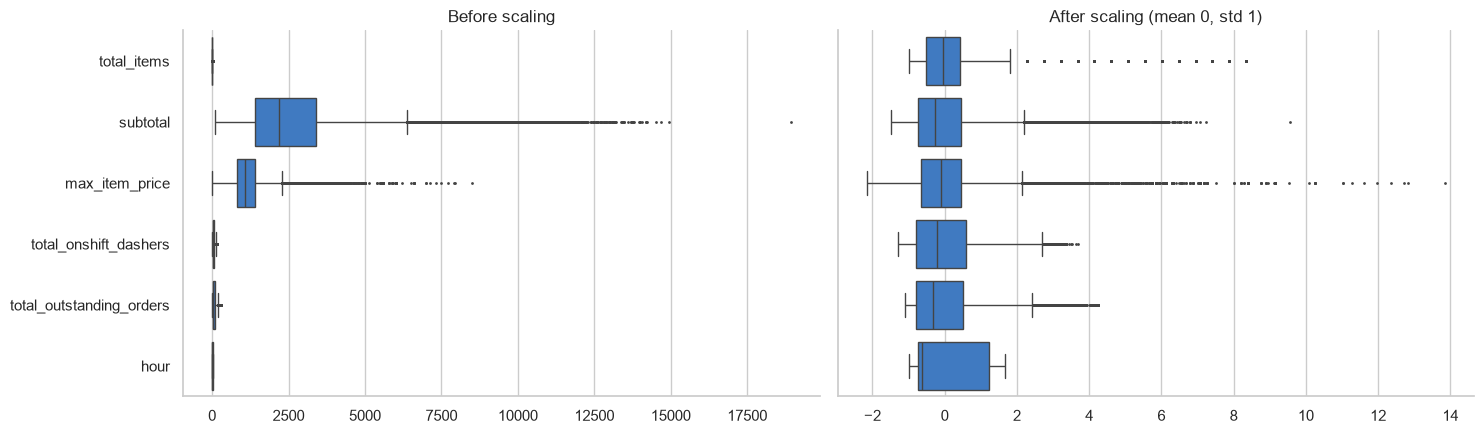

In [67]:
show_cols = ["total_items", "subtotal", "max_item_price", "total_onshift_dashers", "total_outstanding_orders", "hour"]
scaled_df = pd.DataFrame(X_train_s, columns=X.columns)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=X_train_nn[show_cols], orient="h", color=BLUE, fliersize=1, ax=axes[0])
axes[0].set_title("Before scaling")
sns.boxplot(data=scaled_df[show_cols], orient="h", color=BLUE, fliersize=1, ax=axes[1])
axes[1].set_title("After scaling (mean 0, std 1)")
axes[1].set_yticklabels([])
plt.tight_layout()
plt.show()

PyTorch models work with tensors. Features become `float32`. The target is a column of shape `(N, 1)`, which is the shape of the model output. A `DataLoader` hands the model small shuffled batches. `seed_everything` fixes NumPy's and PyTorch's random numbers so that runs can be compared fairly.

In [68]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

def seed_everything(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything()

X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
X_val_t = torch.tensor(X_val_s, dtype=torch.float32)
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)

y_train_t = torch.tensor(y_train_s, dtype=torch.float32)
y_val_t = torch.tensor(y_val_s, dtype=torch.float32)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=256, shuffle=True)

xb, yb = next(iter(train_loader))
print("PyTorch", torch.__version__)
print("One batch -> features:", xb.shape, " targets:", yb.shape)

PyTorch 2.15.0
One batch -> features: torch.Size([256, 24])  targets: torch.Size([256, 1])


From the output above, the data is split into 121,039 training rows, 17,292 validation rows and 34,583 test rows. The scaler and the target scaler were fitted on the training rows only (target mean 46.09, standard deviation 9.22 minutes). One batch holds features of shape (256, 24) and targets of shape (256, 1), which is the shape of the model output.

## 5.2 Defining the Network Architecture and the Activation Functions (Task 5.2, Brief Question 9)

> **Brief Question 9:** *Which activation function did you use and why?*


The baseline network has two hidden layers:

| Layer | Description |
|:--|:--|
| Input | One neuron for each of the 24 input columns |
| Hidden 1 | 128 neurons with ReLU |
| Hidden 2 | 64 neurons with ReLU |
| Output | **1 neuron with no activation** |

**Which activation functions, and why?**

- **Hidden layers: ReLU**, `max(0, z)`. It is cheap, it keeps a gradient of exactly 1 for positive inputs so gradients do not vanish as they do with sigmoid and tanh, and it is the default in most modern networks. Its weakness is that a unit stuck at negative values stops learning (dying ReLU), which Leaky ReLU fixes. We test the alternatives in Section 5.4.
- **Output layer: linear (no activation).** The last neuron decides what the network predicts. A linear last neuron gives regression, and sigmoid or softmax would give classification. A sigmoid would squeeze the answer into 0 to 1, and a ReLU would cut off negative values, which the scaled target can take.

The chart compares the four activation functions we try, and their derivatives (the gradient signal that flows back during training).

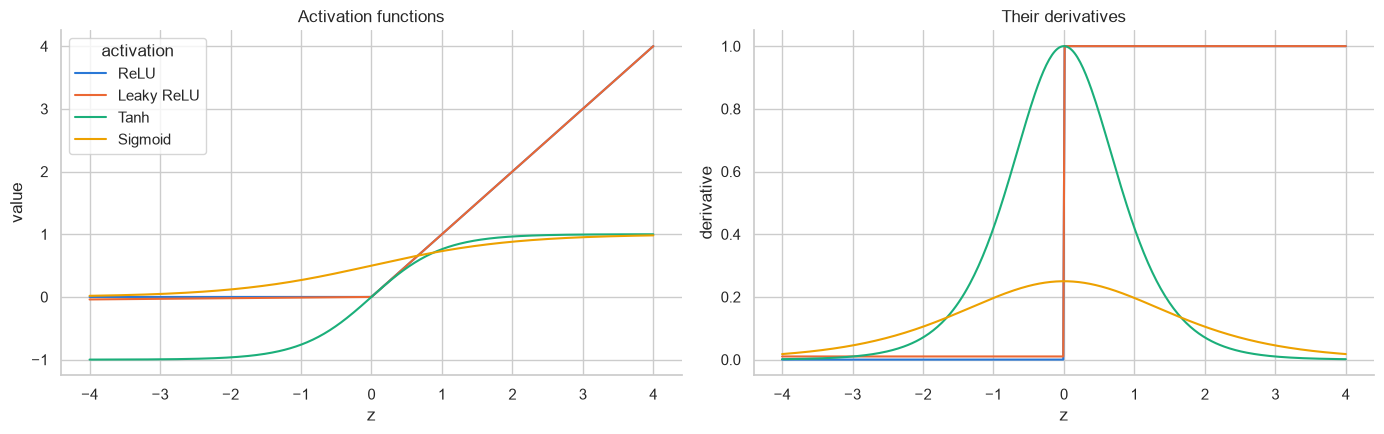

In [69]:
z = torch.linspace(-4, 4, 400, requires_grad=True)
activations = {"ReLU": torch.relu, "Leaky ReLU": lambda t: nn.functional.leaky_relu(t, 0.01), "Tanh": torch.tanh, "Sigmoid": torch.sigmoid}

curves = []
for name, f in activations.items():
    out = f(z)
    grad, = torch.autograd.grad(out.sum(), z)
    curves.append(pd.DataFrame({"z": z.detach().numpy(), "value": out.detach().numpy(), "derivative": grad.numpy(), "activation": name}))
curves = pd.concat(curves)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.lineplot(data=curves, x="z", y="value", hue="activation", palette=[BLUE, ORANGE, AQUA, YELLOW], ax=axes[0])
axes[0].set_title("Activation functions")
sns.lineplot(data=curves, x="z", y="derivative", hue="activation", palette=[BLUE, ORANGE, AQUA, YELLOW], legend=False, ax=axes[1])
axes[1].set_title("Their derivatives")
plt.tight_layout()
plt.show()

`make_net` builds the network from a list of hidden sizes and an activation. As in the course, weights start with Xavier initialisation and biases at zero, and the last layer has **no** activation.

In [70]:
def make_net(hidden=(128, 64), act=nn.ReLU, dropout=0.0, bn=False):
    layers, d = [], X_train_t.shape[1]
    for w in hidden:
        layers.append(nn.Linear(d, w))
        if bn:
            layers.append(nn.BatchNorm1d(w))
        layers.append(act())
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        d = w
    model = nn.Sequential(*layers, nn.Linear(d, 1))        # last layer: no activation
    for layer in model:
        if isinstance(layer, nn.Linear):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)
    return model

torch.manual_seed(0)
model = make_net()
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

Sequential(
  (0): Linear(in_features=24, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=1, bias=True)
)
Trainable parameters: 11521


From the output above, the network has 24 inputs, two ReLU hidden layers of 128 and 64 units, and one linear output neuron. That is 11,521 trainable parameters: 24 x 128 + 128 = 3,200, then 128 x 64 + 64 = 8,256, then 64 + 1 = 65.

## 5.3 Loss Function and Optimizer (Task 5.3, Brief Question 8)

> **Brief Question 8:** *Briefly explain your choice of optimizer.*


- **Loss: `nn.MSELoss()`**, the mean squared error. It is the standard loss for a continuous target, it is smooth, and it punishes big misses more than small ones. We report results as RMSE in minutes, which is easier to read.
- **Optimizer: Adam**, with learning rate 0.001 to start. Plain gradient descent uses one fixed learning rate for every weight and zig-zags on a lopsided loss surface. Momentum smooths the direction, RMSprop shrinks the step where gradients have been large, and **Adam combines both**, with a correction for its first steps. It is a strong default that needs little tuning. Adam still needs a learning rate, so we compare learning rates in Section 5.4.

In [71]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# one forward and backward pass on one batch, before any training
loss = criterion(model(xb), yb)
loss.backward()
print("Loss before training (scaled units):", round(loss.item(), 3))
print("Gradient shapes -> first layer:", tuple(model[0].weight.grad.shape), " last layer:", tuple(model[-1].weight.grad.shape))

Loss before training (scaled units): 1.167
Gradient shapes -> first layer: (128, 24)  last layer: (1, 64)


From the output above, the untrained network has a loss of 1.17 in scaled units. This is close to 1, as expected: an untrained network predicts values near 0 for a target that has been scaled to variance 1, and the random starting weights add a little more. The gradient shapes match the weight shapes ((128, 24) and (1, 64)), so backpropagation is connected properly.

## 5.4 Training the Network and Plotting the Losses (Task 5.4)

We write the training loop ourselves, as in the course. For every batch: `zero_grad`, forward pass, loss, `backward`, `step`. At the end of every epoch we switch to `model.eval()`, measure the error on the training and validation sets with `torch.no_grad()`, and record it in `h`. Errors are recorded as RMSE in minutes. After training, the function loads the weights of the epoch with the lowest validation error.

In [72]:
def fit(model, opt, epochs=40, bs=256):
    loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=bs, shuffle=True)
    h = {"train": [], "val": []}
    best, best_state = float("inf"), None
    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            opt.zero_grad(); criterion(model(xb), yb).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            h["train"].append(criterion(model(X_train_t), y_train_t).item() ** 0.5 * y_std)
            v = criterion(model(X_val_t), y_val_t).item()
            h["val"].append(v ** 0.5 * y_std)
        if v < best:
            best, best_state = v, {k: t.clone() for k, t in model.state_dict().items()}
    if best_state is not None:                       # stays None only if the loss became NaN (diverged)
        model.load_state_dict(best_state)
    h["best_epoch"] = int(np.nanargmin(h["val"])) if np.isfinite(h["val"]).any() else 0
    return h

def show(h, title=""):
    curves = pd.DataFrame({"epoch": range(1, len(h["train"]) + 1), "training": h["train"], "validation": h["val"]})
    curves = curves.melt(id_vars="epoch", var_name="set", value_name="RMSE (minutes)")
    plt.figure(figsize=(9, 4.5))
    sns.lineplot(data=curves, x="epoch", y="RMSE (minutes)", hue="set", palette=[BLUE, ORANGE])
    plt.axvline(h["best_epoch"] + 1, color="#52514e", linestyle=":", linewidth=1.5, label="best epoch")
    plt.title(title)
    plt.legend()
    plt.show()

Let's train the baseline for 60 epochs and plot the training and validation loss.

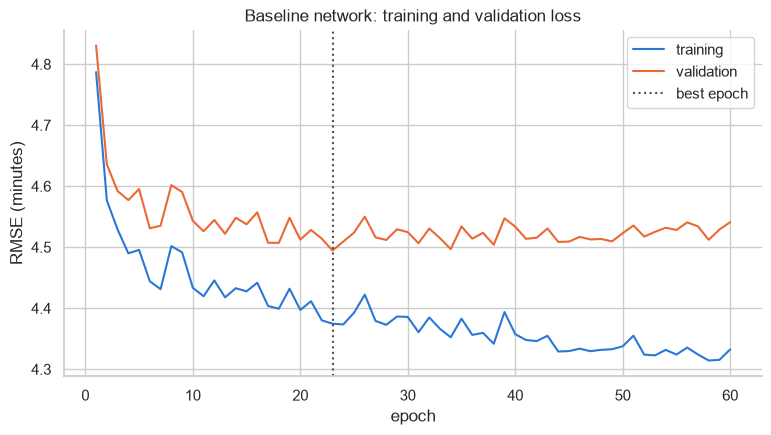

In [73]:
torch.manual_seed(0)
base = make_net()
h_base = fit(base, torch.optim.Adam(base.parameters(), lr=1e-3), epochs=60)
show(h_base, "Baseline network: training and validation loss")

In [74]:
print("Last epoch -> train RMSE", round(h_base["train"][-1], 3), "| validation RMSE", round(h_base["val"][-1], 3), "minutes")
print("Best epoch ->", h_base["best_epoch"] + 1, "with validation RMSE", round(h_base["val"][h_base["best_epoch"]], 3), "minutes")

Last epoch -> train RMSE 4.332 | validation RMSE 4.541 minutes
Best epoch -> 23 with validation RMSE 4.495 minutes


From the output and the chart, the baseline network reaches its best validation RMSE of 4.495 minutes at epoch 23. After that, the training RMSE keeps falling slowly (4.33 at epoch 60) while the validation RMSE stays near 4.5 (4.54 at epoch 60), so a gap of about 0.21 minutes opens up. This is mild overfitting, not a collapse: the validation loss does not climb steeply, and keeping the weights of the best epoch removes the problem.

### Trying Different Configurations

The brief also asks us to try different combinations and hyperparameters. This part belongs to Task 5.4: the network is trained several times, and we keep the best configuration.

We now follow the debugging method from the Practical Aspects class: **change one thing at a time** and keep a scoreboard. Every run starts from the same seed, so differences come from the change and not from luck. Each run trains for 40 epochs and keeps the weights of the best epoch. `run` records the training error, the last validation error, the best validation error and the best epoch.

In [75]:
results = {}
histories = {}
configs = {}

def make_optimizer(params, optimizer, lr, wd=0.0):
    if optimizer == "adam":
        return torch.optim.Adam(params, lr=lr, weight_decay=wd)
    if optimizer == "rmsprop":
        return torch.optim.RMSprop(params, lr=lr, weight_decay=wd)
    if optimizer == "sgd":
        return torch.optim.SGD(params, lr=lr, weight_decay=wd)
    return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=wd)       # "sgd_momentum"

def run(name, group, hidden=(128, 64), act=nn.ReLU, optimizer="adam", lr=1e-3, bs=256, epochs=40, dropout=0.0, bn=False, wd=0.0):
    torch.manual_seed(0)
    m = make_net(hidden, act, dropout, bn)
    opt = make_optimizer(m.parameters(), optimizer, lr, wd)
    h = fit(m, opt, epochs=epochs, bs=bs)
    histories[name] = h
    configs[name] = dict(hidden=hidden, act=act, optimizer=optimizer, lr=lr, bs=bs, dropout=dropout, bn=bn, wd=wd)
    results[name] = [group, h["train"][-1], h["val"][-1], min(h["val"]), h["best_epoch"] + 1]

def scoreboard(group):
    table = pd.DataFrame(results, index=["group", "train_RMSE", "val_RMSE", "best_val_RMSE", "best_epoch"]).T
    table = table[table["group"] == group].drop(columns="group")
    return table.astype(float).round(3)

def plot_group(group, title):
    table = scoreboard(group).sort_values("best_val_RMSE")
    plt.figure(figsize=(9, 0.6 * len(table) + 1.5))
    ax = sns.barplot(x=table["best_val_RMSE"], y=table.index, color=BLUE)
    ax.bar_label(ax.containers[0], fmt="%.3f", fontsize=9)
    plt.title(title)
    plt.xlabel("best validation RMSE (minutes)")
    plt.ylabel("")
    plt.show()

def plot_curves(names, title, palette):
    long = pd.concat([pd.DataFrame({"epoch": range(1, len(histories[n]["val"]) + 1), "validation RMSE": histories[n]["val"], "run": n}) for n in names])
    plt.figure(figsize=(9, 4.5))
    sns.lineplot(data=long, x="epoch", y="validation RMSE", hue="run", palette=palette, linewidth=2)
    plt.title(title)
    plt.show()

#### Experiment 1: Size of the Network

Wider and deeper networks can learn more, but also need more data and time.

In [76]:
for hidden in [(32,), (64, 32), (128, 64), (256, 128, 64), (128, 64, 32, 16)]:
    run(f"size {hidden}", "size", hidden=hidden)

scoreboard("size")

,train_RMSE,val_RMSE,best_val_RMSE,best_epoch
"size (32,)",4.440,4.491,4.482,35.0
"size (64, 32)",4.398,4.493,4.493,25.0
"size (128, 64)",4.357,4.534,4.495,23.0
"size (256, 128, 64)",4.192,4.566,4.513,17.0
"size (128, 64, 32, 16)",4.333,4.536,4.511,27.0


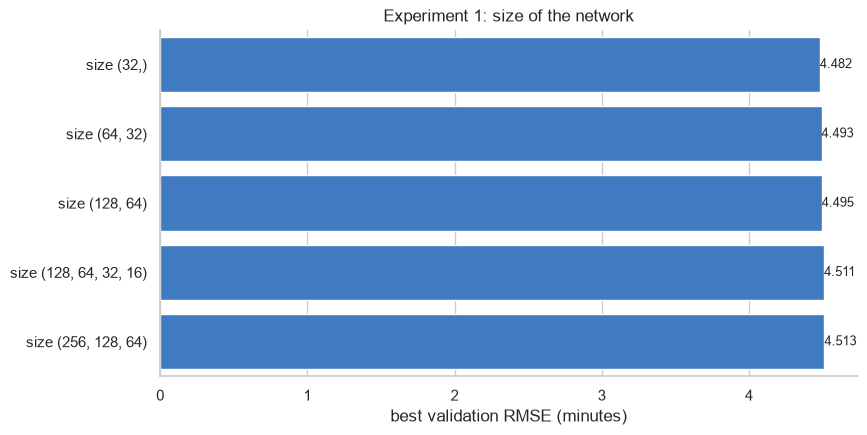

In [77]:
plot_group("size", "Experiment 1: size of the network")

From the scoreboard, all five sizes finish within 0.04 minutes of each other (best validation RMSE 4.482 to 4.513). The smallest network, one hidden layer of 32 units, is the best. The largest, (256, 128, 64), has the lowest training error (4.192) but the highest validation error at its last epoch (4.566), a sign of overfitting. More capacity did not help here.

#### Experiment 2: Activation Function

Same network, only the hidden activation changes.

In [78]:
for name, act in [("ReLU", nn.ReLU), ("Leaky ReLU", nn.LeakyReLU), ("Tanh", nn.Tanh), ("Sigmoid", nn.Sigmoid)]:
    run(f"activation {name}", "activation", act=act)

scoreboard("activation")

,train_RMSE,val_RMSE,best_val_RMSE,best_epoch
activation ReLU,4.357,4.534,4.495,23.0
activation Leaky ReLU,4.362,4.533,4.494,23.0
activation Tanh,4.416,4.525,4.497,34.0
activation Sigmoid,4.442,4.495,4.490,38.0


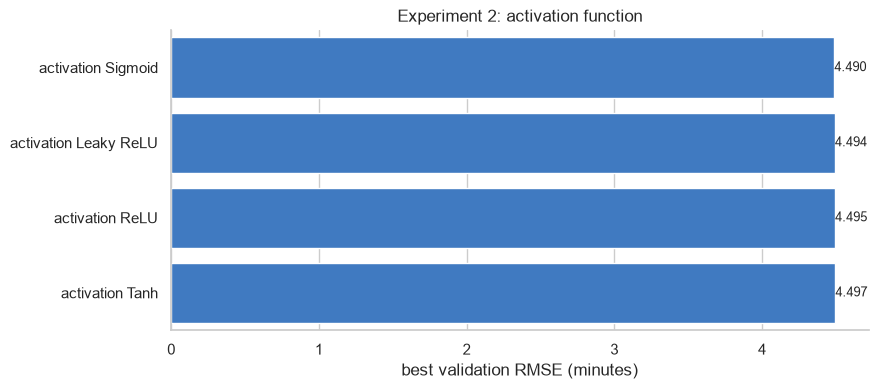

In [79]:
plot_group("activation", "Experiment 2: activation function")

From the scoreboard, the four activations are within 0.007 minutes of each other (4.490 to 4.497). ReLU and Leaky ReLU reach their best epoch at epoch 23, Tanh at epoch 34 and Sigmoid at epoch 38, so Sigmoid trains the most slowly. The gaps are too small to call a winner from one run each, so we keep ReLU for the reasons given in Section 5.2.

#### Experiment 3: The Optimiser Race

The same network with four optimisers, as in the SwiftLend case: plain SGD (learning rate 0.01), SGD with momentum (learning rate 0.001), RMSprop (0.001) and Adam (0.001). Momentum makes the effective step larger. We first tried it with a learning rate of 0.01, and on this target the training diverged (the loss became NaN), so we use 0.001.

In [80]:
run("optimiser SGD", "optimiser", optimizer="sgd", lr=0.01)
run("optimiser SGD + Momentum", "optimiser", optimizer="sgd_momentum", lr=1e-3)
run("optimiser RMSprop", "optimiser", optimizer="rmsprop", lr=1e-3)
run("optimiser Adam", "optimiser", optimizer="adam", lr=1e-3)

scoreboard("optimiser")

,train_RMSE,val_RMSE,best_val_RMSE,best_epoch
optimiser SGD,4.469,4.550,4.540,39.0
optimiser SGD + Momentum,4.456,4.537,4.537,39.0
optimiser RMSprop,4.376,4.577,4.509,38.0
optimiser Adam,4.357,4.534,4.495,23.0


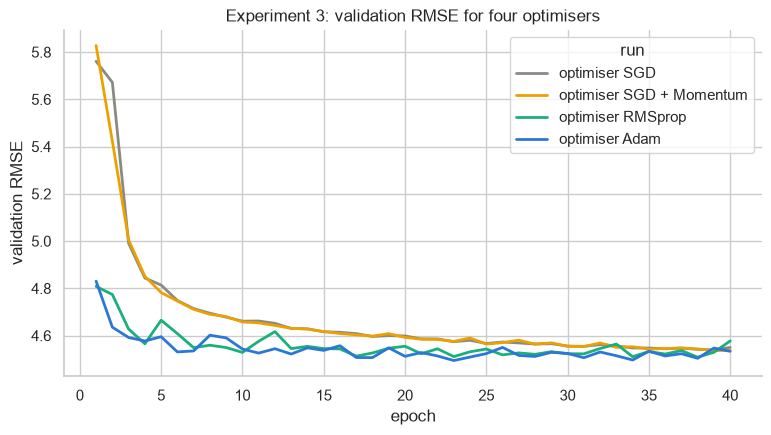

In [81]:
plot_curves(["optimiser SGD", "optimiser SGD + Momentum", "optimiser RMSprop", "optimiser Adam"],
            "Experiment 3: validation RMSE for four optimisers", [GRAY, YELLOW, AQUA, BLUE])

From the scoreboard, Adam (4.495) and RMSprop (4.509) beat plain SGD (4.540) and SGD with momentum (4.537), which were still improving at epoch 39 of 40 and would need more epochs or a larger learning rate. SGD with momentum at learning rate 0.01 did not train at all: the loss became NaN from the first epoch (we re-ran it for five epochs to confirm), which is why that run uses 0.001. This is the practical reason to choose Adam: it gives a good result quickly without careful tuning of the learning rate.

#### Experiment 4: Learning Rate

The learning rate is the first hyperparameter to tune. As in the Practical Aspects class we try values that differ by large factors, a log-scale spread, with Adam.

In [82]:
for lr in [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]:
    run(f"learning rate {lr:g}", "learning rate", lr=lr)

scoreboard("learning rate")

,train_RMSE,val_RMSE,best_val_RMSE,best_epoch
learning rate 0.0001,4.424,4.531,4.528,39.0
learning rate 0.0003,4.374,4.524,4.512,23.0
learning rate 0.001,4.357,4.534,4.495,23.0
learning rate 0.003,4.380,4.546,4.495,18.0
learning rate 0.01,4.440,4.516,4.497,34.0


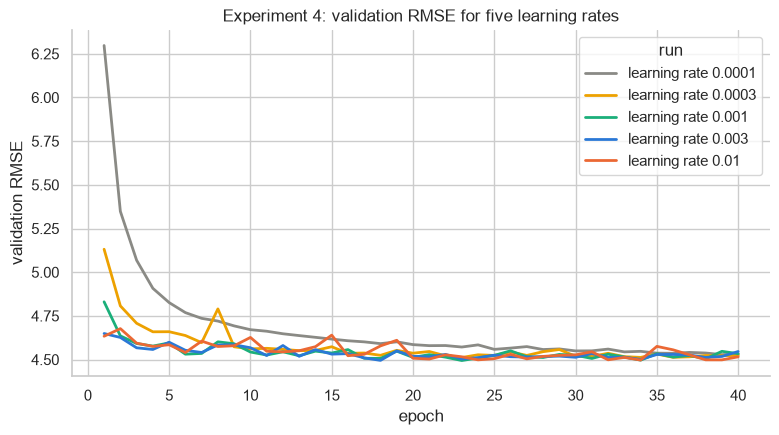

In [83]:
plot_curves([f"learning rate {lr:g}" for lr in [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]],
            "Experiment 4: validation RMSE for five learning rates", [GRAY, YELLOW, AQUA, BLUE, ORANGE])

From the scoreboard, learning rates from 0.0003 to 0.01 all land between 4.495 and 4.512, and 0.001 and 0.003 tie for the best (4.495). Only 0.0001 is clearly slower (4.528, best epoch 39, still improving). A wide range works because Adam adapts the step for every weight and the inputs are standardised.

#### Experiment 5: Batch Size

A small batch updates the weights more often but with noisier gradients. A large batch gives smoother gradients and a faster epoch, but fewer updates.

In [84]:
for bs in [64, 128, 256, 512, 1024]:
    run(f"batch size {bs}", "batch size", bs=bs)

scoreboard("batch size")

,train_RMSE,val_RMSE,best_val_RMSE,best_epoch
batch size 64,4.349,4.555,4.496,17.0
batch size 128,4.347,4.529,4.492,23.0
batch size 256,4.357,4.534,4.495,23.0
batch size 512,4.365,4.526,4.503,36.0
batch size 1024,4.378,4.523,4.497,35.0


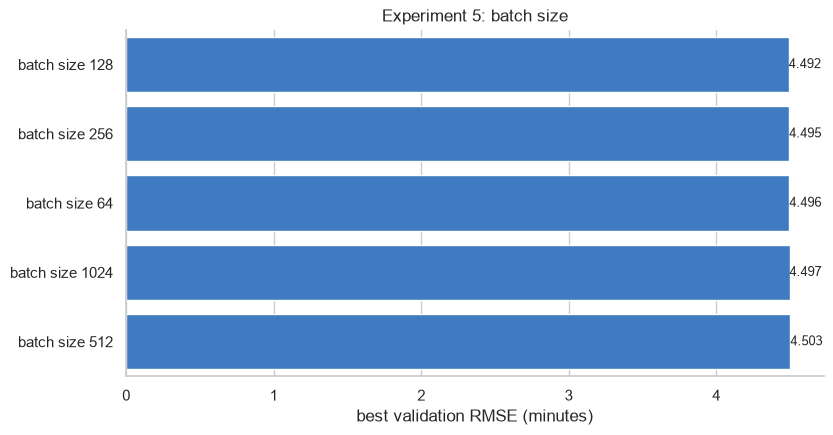

In [85]:
plot_group("batch size", "Experiment 5: batch size")

From the scoreboard, batch sizes from 64 to 1024 all finish between 4.492 and 4.503, so batch size hardly matters here. The two largest batches reach their best epoch later (epochs 36 and 35 for 512 and 1024, against epochs 17 to 23 for 64 to 256) because they make fewer weight updates per epoch.

#### Experiment 6: Regularisation

The baseline network showed a small gap between its training and validation error. Three standard remedies from the Hyperparameter Tuning class can shrink such a gap: **weight decay** (an L2 penalty that keeps the weights small, set with Adam's `weight_decay`), **dropout** (randomly switching off a share of the neurons while training, and off again when predicting) and **batch normalisation** (standardising the values inside the network). We apply them one at a time to the baseline network (128, 64).

In [86]:
run("regularisation weight decay 1e-4", "regularisation", wd=1e-4)
run("regularisation weight decay 1e-3", "regularisation", wd=1e-3)
run("regularisation dropout 0.1", "regularisation", dropout=0.1)
run("regularisation dropout 0.3", "regularisation", dropout=0.3)
run("regularisation batch norm", "regularisation", bn=True)

scoreboard("regularisation")

,train_RMSE,val_RMSE,best_val_RMSE,best_epoch
regularisation weight decay 1e-4,4.384,4.516,4.488,34.0
regularisation weight decay 1e-3,4.446,4.515,4.487,34.0
regularisation dropout 0.1,4.391,4.490,4.488,36.0
regularisation dropout 0.3,4.421,4.485,4.485,40.0
regularisation batch norm,4.374,4.528,4.500,38.0


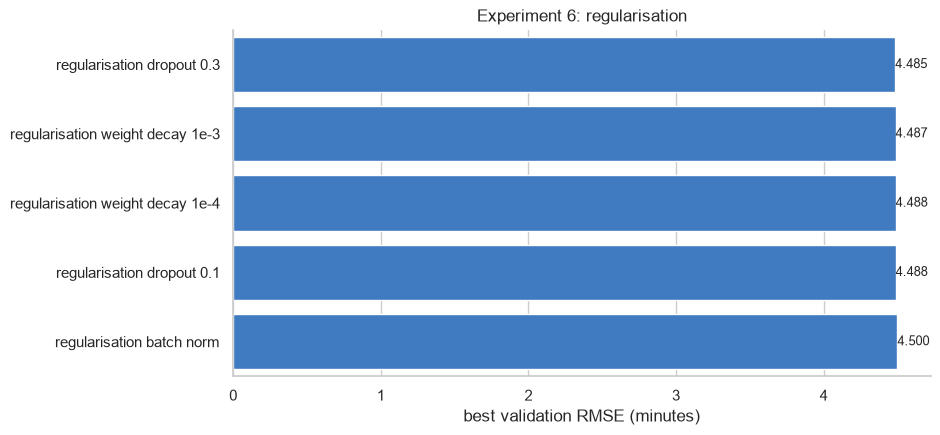

In [87]:
plot_group("regularisation", "Experiment 6: regularisation")

From the scoreboard, all five regularised networks land within 0.015 minutes of each other (4.485 to 4.500), against 4.495 for the same network without regularisation. Dropout 0.3 is the best of them (4.485) and it shrinks the gap between training and validation error at the last epoch from 0.18 to 0.06 minutes, so it does what it should, but the gain in validation error is only 0.010 minutes. Batch normalisation is slightly worse than no regularisation (4.500), as it also was in the SwiftLend case study. None of them beats the small 32-unit network (4.482): a small network is itself a form of regularisation.

#### The Full Scoreboard

Every run from the six experiments in one chart, coloured by experiment.

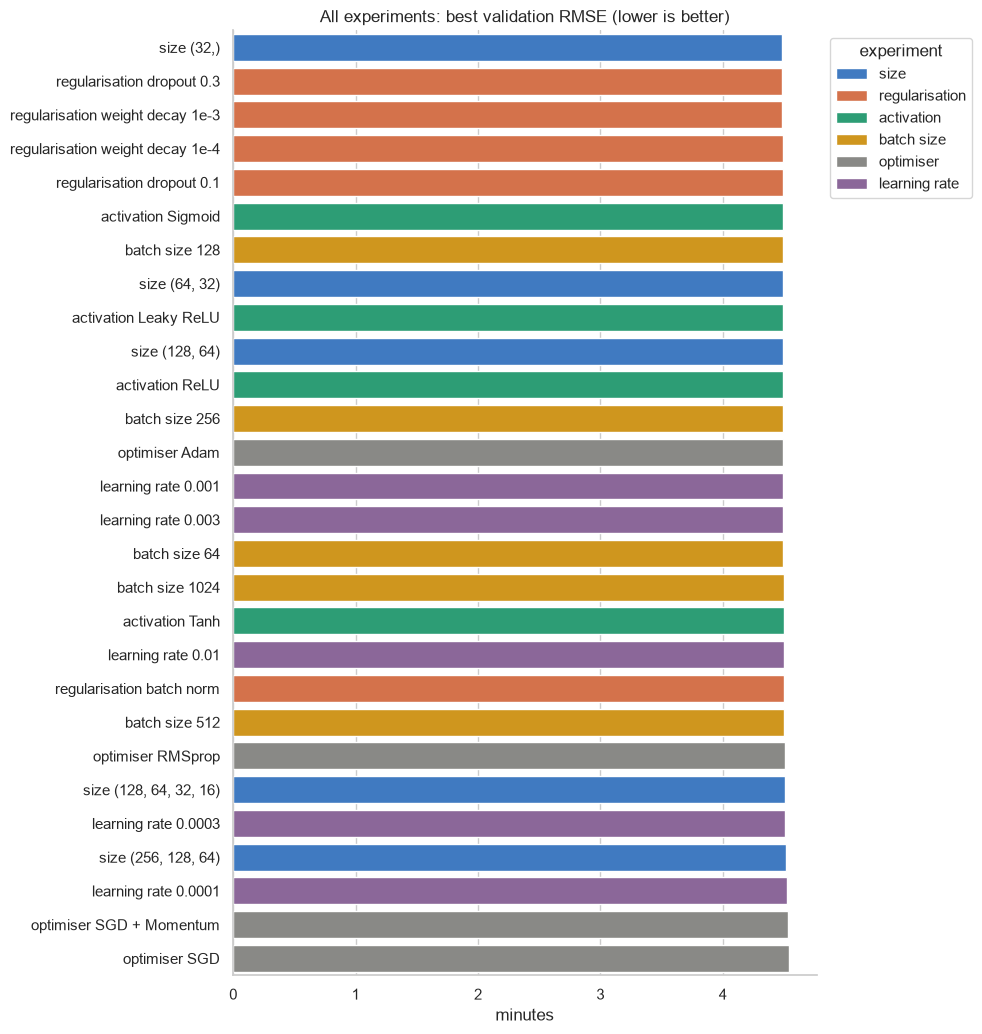

,group,train_RMSE,val_RMSE,best_val_RMSE,best_epoch
"size (32,)",size,4.440,4.491,4.482,35.0
regularisation dropout 0.3,regularisation,4.421,4.485,4.485,40.0
regularisation weight decay 1e-3,regularisation,4.446,4.515,4.487,34.0
regularisation weight decay 1e-4,regularisation,4.384,4.516,4.488,34.0
regularisation dropout 0.1,regularisation,4.391,4.490,4.488,36.0


In [88]:
board = pd.DataFrame(results, index=["group", "train_RMSE", "val_RMSE", "best_val_RMSE", "best_epoch"]).T
board[["train_RMSE", "val_RMSE", "best_val_RMSE", "best_epoch"]] = board[["train_RMSE", "val_RMSE", "best_val_RMSE", "best_epoch"]].astype(float)
board = board.sort_values("best_val_RMSE")

plt.figure(figsize=(10, 10.5))
sns.barplot(data=board, x="best_val_RMSE", y=board.index, hue="group", dodge=False,
            palette=[BLUE, ORANGE, AQUA, YELLOW, GRAY, "#8e5ea2"])
plt.title("All experiments: best validation RMSE (lower is better)")
plt.xlabel("minutes")
plt.ylabel("")
plt.legend(title="experiment", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

board.head(5).round(3)

From the chart, there are 28 runs (five of them are the same baseline configuration, counted once in each experiment). Their best validation RMSE runs from 4.482 to 4.540 minutes, a spread of 0.06 minutes (about 1.3%). The bars start at zero on purpose, so that the chart does not exaggerate the gaps: no single hyperparameter matters much for this problem, and the order of the top few runs should not be over-read. Choosing the best run by **validation** error is still the right rule, because the test set must not be used for choosing.

### The Final Model

We take the configuration with the lowest validation error on the scoreboard and train it for 60 epochs. The weights of the best epoch are kept, and the loss curves are plotted. The test set is not used for any of these choices.

In [89]:
best_name = board.index[0]
best_cfg = configs[best_name]
print("Best configuration:", best_name)
print(best_cfg)

Best configuration: size (32,)
{'hidden': (32,), 'act': <class 'torch.nn.modules.activation.ReLU'>, 'optimizer': 'adam', 'lr': 0.001, 'bs': 256, 'dropout': 0.0, 'bn': False, 'wd': 0.0}


Best epoch: 53 | validation RMSE: 4.472 minutes


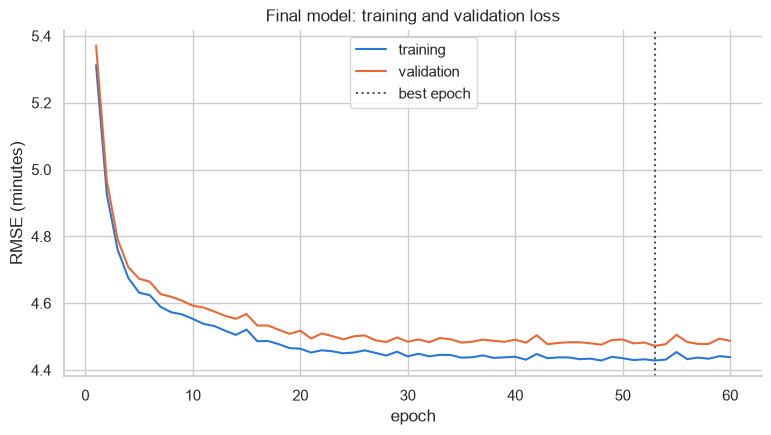

In [90]:
torch.manual_seed(0)
final = make_net(best_cfg["hidden"], best_cfg["act"], best_cfg["dropout"], best_cfg["bn"])
final_opt = make_optimizer(final.parameters(), best_cfg["optimizer"], best_cfg["lr"], best_cfg["wd"])

h_final = fit(final, final_opt, epochs=60, bs=best_cfg["bs"])
print("Best epoch:", h_final["best_epoch"] + 1, "| validation RMSE:", round(min(h_final["val"]), 3), "minutes")
show(h_final, "Final model: training and validation loss")

From the output above, the best configuration on the scoreboard is one hidden layer of 32 units with ReLU, Adam (learning rate 0.001), batch size 256 and no regularisation. That network has only 833 parameters. Trained for 60 epochs, its best epoch is 53 with a validation RMSE of 4.472 minutes. The training and validation curves lie on top of each other, so this small network does not overfit: it is limited by what the features can explain, not by memorisation.

## 5.5 Test Evaluation and Comparison with the Random Forest (Task 5.5)

Now, once, we use the test set. The network predicts in scaled units, so `y_scaler.inverse_transform` converts the predictions back to minutes. Both models are scored with exactly the same metrics on exactly the same test rows.

In [91]:
final.eval()
with torch.no_grad():
    nn_test_pred = y_scaler.inverse_transform(final(X_test_t).numpy()).ravel()

nn_test_res = regression_report(y_test, nn_test_pred)

comparison = pd.DataFrame({"Random Forest": rf_test_res, "Neural Network": nn_test_res})
comparison.round(3)

,Random Forest,Neural Network
MSE,22.015,19.735
RMSE,4.692,4.442
MAE,3.678,3.494
R2,0.744,0.770
MAPE_percent,8.135,7.713


The chart compares the two models on the three error metrics of the brief.

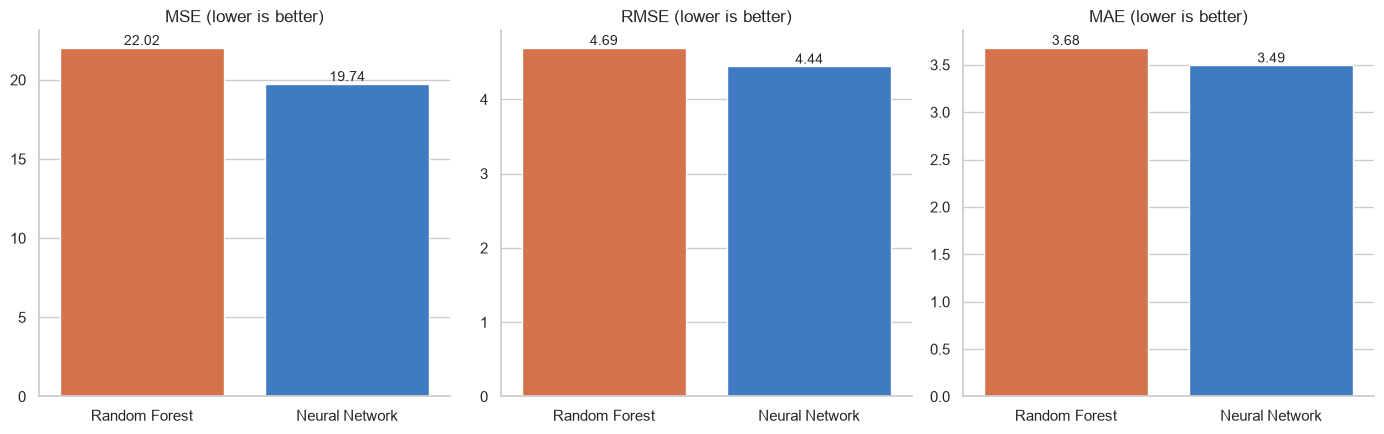

In [92]:
bars = comparison.loc[["MSE", "RMSE", "MAE"]].reset_index().melt(id_vars="index", var_name="model", value_name="value")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, metric in zip(axes, ["MSE", "RMSE", "MAE"]):
    sns.barplot(data=bars[bars["index"] == metric], x="model", y="value", hue="model",
                palette={"Random Forest": ORANGE, "Neural Network": BLUE}, legend=False, ax=ax)
    ax.bar_label(ax.containers[0], fmt="%.2f", fontsize=10)
    ax.bar_label(ax.containers[1], fmt="%.2f", fontsize=10)
    ax.set_title(f"{metric} (lower is better)")
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

Predicted against actual for each model, with the dashed diagonal as the perfect prediction.

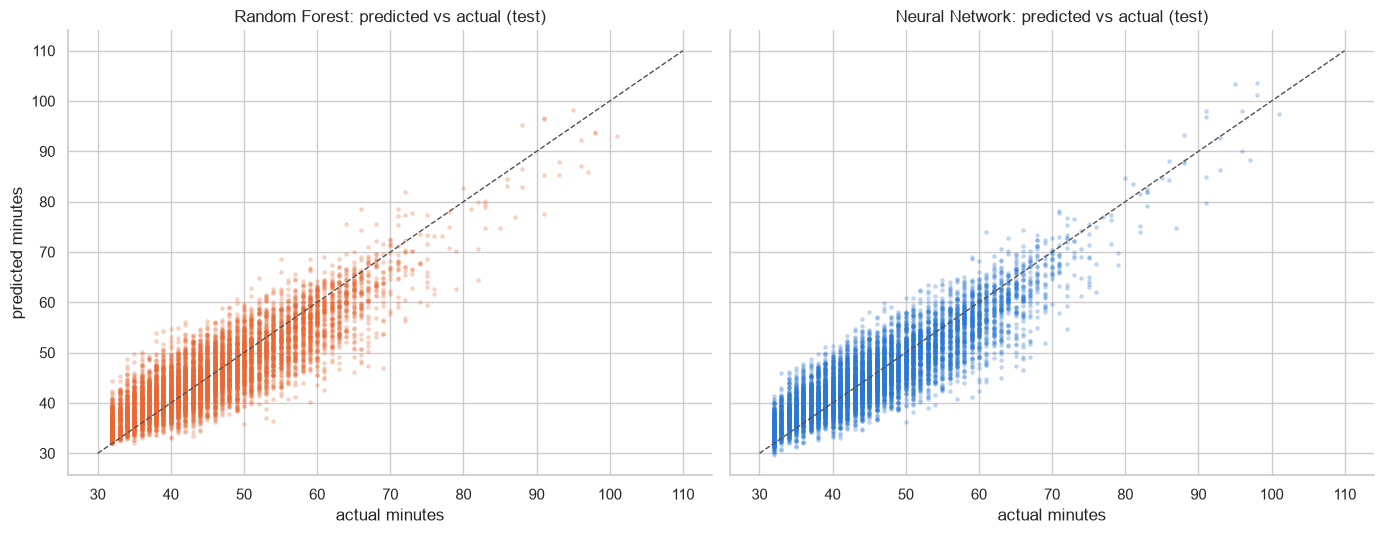

In [93]:
pred_frame = pd.DataFrame({"actual": y_test.values, "Random Forest": rf_test_pred, "Neural Network": nn_test_pred})
sample = pred_frame.sample(8000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for ax, name, color in zip(axes, ["Random Forest", "Neural Network"], [ORANGE, BLUE]):
    sns.scatterplot(data=sample, x="actual", y=name, s=8, alpha=0.3, color=color, edgecolor=None, ax=ax)
    ax.plot([30, 110], [30, 110], color="#52514e", linestyle="--", linewidth=1)
    ax.set_title(f"{name}: predicted vs actual (test)")
    ax.set_xlabel("actual minutes")
    ax.set_ylabel("predicted minutes")
plt.tight_layout()
plt.show()

The distribution of the errors (actual minus predicted) for both models.

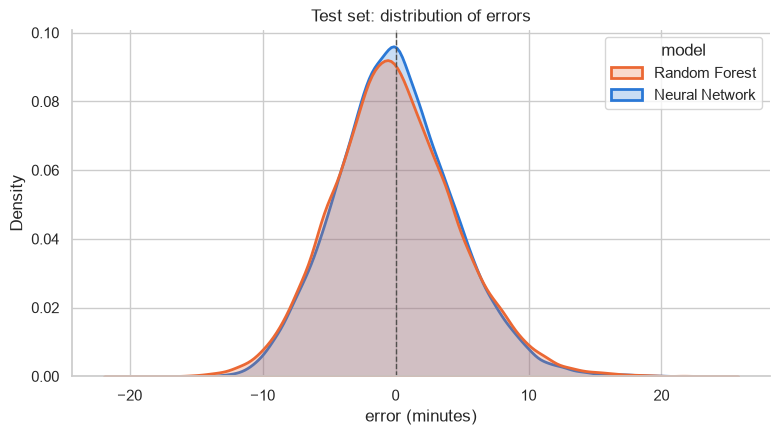

In [94]:
errors = pd.DataFrame({"Random Forest": y_test.values - rf_test_pred, "Neural Network": y_test.values - nn_test_pred})
errors_long = errors.melt(var_name="model", value_name="error (minutes)")

plt.figure(figsize=(9, 4.5))
sns.kdeplot(data=errors_long, x="error (minutes)", hue="model", palette={"Random Forest": ORANGE, "Neural Network": BLUE},
            fill=True, alpha=0.25, common_norm=False, linewidth=2)
plt.axvline(0, color="#52514e", linestyle="--", linewidth=1)
plt.title("Test set: distribution of errors")
plt.show()

From the output above, on the same 34,583 test rows the neural network is slightly better on every metric: RMSE 4.44 against 4.69 minutes, MAE 3.49 against 3.68, R² 0.770 against 0.744 and MAPE 7.7% against 8.1%. Its MSE is 19.7 against 22.0, about 10% lower.

The improvement is small in minutes (about 0.25 minutes of RMSE, or 5%), and both models make the same kind of mistake: they tend to predict too low for very slow deliveries (above about 70 minutes), as the predicted-against-actual charts show. Both explain about three quarters of the variation in delivery time. The forest fits its training rows far better than its test rows (RMSE 1.76 against 4.69), while the network's training and validation errors are almost equal. The next six tests ask whether this small lead is real.

### Is the Network Really Better? More Evidence

The table above shows that the network scores a little better. One test split cannot tell us whether that gap is real or luck, so we look at the question from six more sides, and we report each result as it comes out.

**Evidence 1: what the customer experiences.** An average error hides how often the promise is good enough. We count the share of test orders predicted within 3, 5 and 10 minutes of the real time, and how often the order arrives **more than 5 minutes later than promised** (the prediction was too low).

In [95]:
y_true = y_test.values
preds = {"Random Forest": rf_test_pred, "Neural Network": nn_test_pred}

def customer_view(pred):
    err = y_true - pred
    return {"within 3 min (%)": np.mean(np.abs(err) <= 3) * 100,
            "within 5 min (%)": np.mean(np.abs(err) <= 5) * 100,
            "within 10 min (%)": np.mean(np.abs(err) <= 10) * 100,
            "arrives > 5 min later than promised (%)": np.mean(err > 5) * 100}

pd.DataFrame({name: customer_view(p) for name, p in preds.items()}).round(2)

,Random Forest,Neural Network
within 3 min (%),49.72,51.51
within 5 min (%),72.39,74.67
within 10 min (%),96.53,97.62
arrives > 5 min later than promised (%),13.44,12.68


From the table, the network puts more orders inside every error band: 51.5% against 49.7% within 3 minutes, 74.7% against 72.4% within 5 minutes and 97.6% against 96.5% within 10 minutes. It also breaks its promise by more than 5 minutes less often (12.7% of orders against 13.4%). For a customer the gain is small but it points the same way: about two more orders in a hundred land within 5 minutes of the estimate.

**Evidence 2: is the gap bigger than the luck of the test sample?** We draw 1,000 new test sets by sampling the test rows with replacement (a *paired bootstrap*: both models are scored on exactly the same rows each time) and record how much lower the network's error is. If the 95% interval stays above zero, the network's lead is not a lucky draw of test rows.

In [96]:
rng = np.random.default_rng(42)
se_rf, se_nn = (y_true - rf_test_pred) ** 2, (y_true - nn_test_pred) ** 2
ae_rf, ae_nn = np.abs(y_true - rf_test_pred), np.abs(y_true - nn_test_pred)

rmse_gain, mae_gain = [], []
for _ in range(1000):
    i = rng.integers(0, len(y_true), len(y_true))
    rmse_gain.append(np.sqrt(se_rf[i].mean()) - np.sqrt(se_nn[i].mean()))
    mae_gain.append(ae_rf[i].mean() - ae_nn[i].mean())

boot = pd.DataFrame({"RMSE": rmse_gain, "MAE": mae_gain})
summary_boot = pd.DataFrame({"mean gain (min)": boot.mean(),
                             "95% lower": boot.quantile(0.025),
                             "95% upper": boot.quantile(0.975),
                             "share of draws where the network wins (%)": (boot > 0).mean() * 100})
summary_boot.round(3)

,mean gain (min),95% lower,95% upper,share of draws where the network wins (%)
RMSE,0.250,0.229,0.271,100.0
MAE,0.185,0.168,0.203,100.0


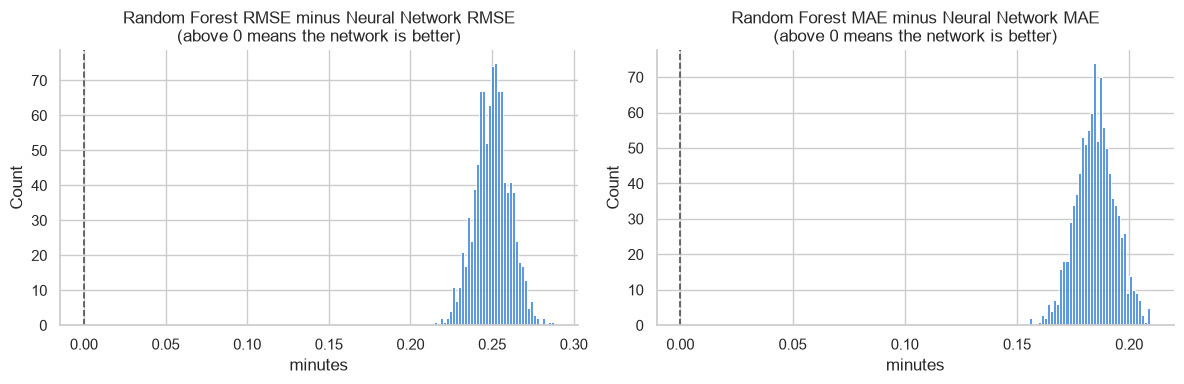

In [97]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["RMSE", "MAE"]):
    sns.histplot(boot[col], bins=40, color=BLUE, ax=ax)
    ax.axvline(0, color="#52514e", linestyle="--", linewidth=1.2)
    ax.set_title(f"Random Forest {col} minus Neural Network {col}\n(above 0 means the network is better)")
    ax.set_xlabel("minutes")
plt.tight_layout()
plt.show()

From the table and the chart, the network's RMSE is lower by 0.250 minutes on average, with a 95% interval of 0.229 to 0.271, and its MAE is lower by 0.185 minutes (0.168 to 0.203). In all 1,000 resampled test sets the network wins, and the whole interval lies above zero. So the lead is not the luck of which rows ended up in the test set. This test only covers the choice of test rows: it does not cover the choice of training rows or the random start, which the next test looks at.

**Evidence 3: is it just a lucky seed?** A neural network starts from random weights and a forest from random trees, so each result depends on the seed. We train the final network with 5 different seeds and the forest with 4 different seeds, keep the same split, and look at the spread of the test RMSE.

In [98]:
def final_net_rmse(seed):
    torch.manual_seed(seed)
    m = make_net(best_cfg["hidden"], best_cfg["act"], best_cfg["dropout"], best_cfg["bn"])
    fit(m, make_optimizer(m.parameters(), best_cfg["optimizer"], best_cfg["lr"], best_cfg["wd"]), epochs=60, bs=best_cfg["bs"])
    m.eval()
    with torch.no_grad():
        p = y_scaler.inverse_transform(m(X_test_t).numpy()).ravel()
    return regression_report(y_test, p)["RMSE"]

nn_rmse = [nn_test_res["RMSE"]] + [final_net_rmse(sd) for sd in [1, 2, 3, 4]]
rf_rmse = [rf_test_res["RMSE"]]
for sd in [1, 2, 3]:
    rf_sd = RandomForestRegressor(n_estimators=100, random_state=sd, n_jobs=-1).fit(X_train, y_train)
    rf_rmse.append(regression_report(y_test, rf_sd.predict(X_test))["RMSE"])

seed_table = pd.DataFrame({
    "runs": [len(rf_rmse), len(nn_rmse)],
    "mean test RMSE": [np.mean(rf_rmse), np.mean(nn_rmse)],
    "std between runs": [np.std(rf_rmse, ddof=1), np.std(nn_rmse, ddof=1)],
    "best run": [min(rf_rmse), min(nn_rmse)],
    "worst run": [max(rf_rmse), max(nn_rmse)],
}, index=["Random Forest", "Neural Network"])
seed_table.round(3)

,runs,mean test RMSE,std between runs,best run,worst run
Random Forest,4,4.693,0.004,4.688,4.697
Neural Network,5,4.445,0.007,4.434,4.454


From the table, the network's test RMSE moves very little between seeds (4.434 to 4.454, standard deviation 0.007) and so does the forest's (4.688 to 4.697, standard deviation 0.004). The **worst** of the 5 network runs (4.454) is better than the **best** of the 4 forest runs (4.688), by 0.23 minutes. So the difference is not a lucky seed. All runs use the same train and test split, so this still does not show how much a different split would change the numbers.

**Evidence 4: how much model is needed, and how fast is it?** A model that reaches the same accuracy with far fewer numbers is cheaper to store and faster to run when thousands of customers ask for an estimate at once. We compare the size, the time to predict the test orders, and the gap between training and test error (a large gap means the model memorised its training data).

In [99]:
import time

def predict_time(fn, repeats=5):
    best = float("inf")
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); best = min(best, time.perf_counter() - t0)
    return best

def nn_predict():
    with torch.no_grad():
        return final(X_test_t)

with torch.no_grad():
    nn_train_pred = y_scaler.inverse_transform(final(X_train_t).numpy()).ravel()
nn_train_rmse = regression_report(y_train_nn, nn_train_pred)["RMSE"]

rf_nodes = sum(tree.tree_.node_count for tree in rf.estimators_)
nn_params = sum(p.numel() for p in final.parameters())

pd.DataFrame({
    "Random Forest": {"stored numbers": rf_nodes, "predict all test orders (seconds)": predict_time(lambda: rf.predict(X_test)),
                      "train RMSE": rf_train_res["RMSE"], "test RMSE": rf_test_res["RMSE"], "gap (test - train)": rf_test_res["RMSE"] - rf_train_res["RMSE"]},
    "Neural Network": {"stored numbers": nn_params, "predict all test orders (seconds)": predict_time(nn_predict),
                       "train RMSE": nn_train_rmse, "test RMSE": nn_test_res["RMSE"], "gap (test - train)": nn_test_res["RMSE"] - nn_train_rmse},
}).round(3)

,Random Forest,Neural Network
stored numbers,1.373706e+07,833.000
predict all test orders (seconds),1.620000e-01,0.001
train RMSE,1.763000e+00,4.428
test RMSE,4.692000e+00,4.442
gap (test - train),2.929000e+00,0.014


From the table, the network is far smaller and faster. The forest stores about 13.7 million tree nodes and the network 833 weights (these are different kinds of numbers, so read this as the order of magnitude, not as an exact ratio). Predicting all the test orders took about 0.17 seconds for the forest and about 0.001 seconds for the network on this computer (timings change a little from run to run). The forest's test error is 2.93 minutes above its training error, while the network's test error is only 0.014 minutes above its own, which shows how much more the forest memorises its training rows.

**Evidence 5: does the lead hold when the market is quiet and when it is busy?** A model that wins on average but fails when the market is busy would be a poor choice. We split the test orders into four equal groups by the number of orders waiting (`total_outstanding_orders`) and compare the RMSE of both models in each group.

In [100]:
busy = pd.qcut(X_test["total_outstanding_orders"], 4, labels=["quietest 25%", "quiet", "busy", "busiest 25%"])

rows = {}
for label in busy.cat.categories:
    mask = (busy == label).values
    rows[label] = {"orders": int(mask.sum()),
                   "Random Forest RMSE": np.sqrt(np.mean((y_true[mask] - rf_test_pred[mask]) ** 2)),
                   "Neural Network RMSE": np.sqrt(np.mean((y_true[mask] - nn_test_pred[mask]) ** 2))}
by_busy = pd.DataFrame(rows).T
by_busy["network better by (min)"] = by_busy["Random Forest RMSE"] - by_busy["Neural Network RMSE"]
by_busy.round(3)

,orders,Random Forest RMSE,Neural Network RMSE,network better by (min)
quietest 25%,8652.0,5.071,4.859,0.212
quiet,8806.0,4.970,4.756,0.213
busy,8587.0,4.690,4.405,0.285
busiest 25%,8538.0,3.940,3.629,0.311


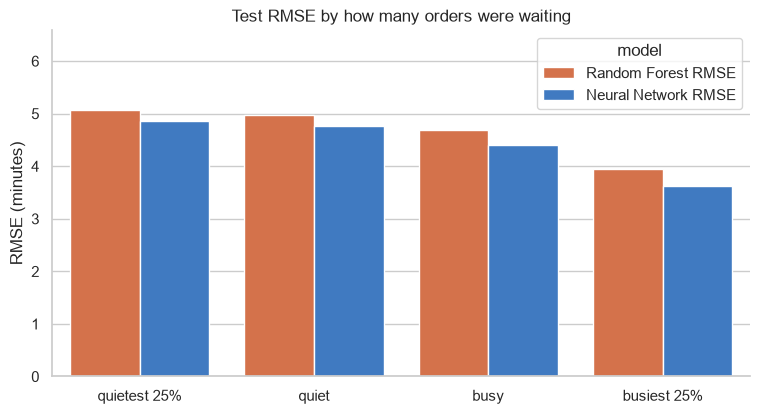

In [101]:
plot_busy = by_busy[["Random Forest RMSE", "Neural Network RMSE"]].reset_index().melt(id_vars="index", var_name="model", value_name="RMSE (minutes)")
plt.figure(figsize=(9, 4.5))
sns.barplot(data=plot_busy, x="index", y="RMSE (minutes)", hue="model", palette=[ORANGE, BLUE])
plt.ylim(0, plot_busy["RMSE (minutes)"].max() * 1.3)
plt.title("Test RMSE by how many orders were waiting")
plt.xlabel("")
plt.show()

From the table and the chart, the network is better in all four groups, by 0.21 minutes when the market is quiet, 0.29 when it is busy and 0.31 when it is busiest, so its lead is largest when accurate estimates matter most. Both models are least accurate when few orders are waiting (RMSE 4.9 to 5.1) and most accurate when the market is busiest (3.6 to 3.9).

**Evidence 6: is the forest being treated fairly?** Our Random Forest used the default settings and overfits (its training error is far below its test error). A fair comparison should give it a chance to do better. We try forests with at least 1, 5, 10 or 20 rows per leaf and with all or half of the features at each split, choose the best by the **validation** error (the same validation rows the network used), and only then score that forest on the test set once.

In [102]:
tune_rows = []
for leaf in [1, 5, 10, 20]:
    for feats in [1.0, 0.5]:
        m = RandomForestRegressor(n_estimators=200, min_samples_leaf=leaf, max_features=feats, random_state=42, n_jobs=-1).fit(X_train_nn, y_train_nn)
        tune_rows.append({"min_samples_leaf": leaf, "max_features": feats,
                          "validation RMSE": regression_report(y_val, m.predict(X_val))["RMSE"], "model": m})
tune = pd.DataFrame(tune_rows)
tuned_rf = tune.loc[tune["validation RMSE"].idxmin(), "model"]
tune.drop(columns="model").round(3)

,min_samples_leaf,max_features,validation RMSE
0,1,1.0,4.723
1,1,0.5,4.695
2,5,1.0,4.706
3,5,0.5,4.691
4,10,1.0,4.722
5,10,0.5,4.734
6,20,1.0,4.782
7,20,0.5,4.814


In [103]:
tuned_res = regression_report(y_test, tuned_rf.predict(X_test))
print("Chosen forest:", tuned_rf.get_params()["min_samples_leaf"], "rows per leaf, max_features =", tuned_rf.get_params()["max_features"])

pd.DataFrame({"Random Forest (default)": rf_test_res, "Random Forest (tuned)": tuned_res, "Neural Network": nn_test_res}).round(3)

Chosen forest: 5 rows per leaf, max_features = 0.5


,Random Forest (default),Random Forest (tuned),Neural Network
MSE,22.015,21.658,19.735
RMSE,4.692,4.654,4.442
MAE,3.678,3.665,3.494
R2,0.744,0.748,0.770
MAPE_percent,8.135,8.104,7.713


From the tables, the best forest on the validation rows has at least 5 rows per leaf and half of the features at each split (validation RMSE 4.691). Scored once on the test rows, it improves a little on the default forest (RMSE 4.654 against 4.692, MAE 3.665 against 3.678) but the network is still ahead (RMSE 4.442, MAE 3.494, R² 0.770 against 0.748). Together with Gradient Boosting (4.573, Section 4.4), this means the network's lead does not come from a poorly set-up baseline.

### Verdict: Which Model Is Stronger?

**The neural network is the stronger model here**, and the evidence is consistent:

| Evidence | Random Forest | Neural Network |
|:--|:--:|:--:|
| Test RMSE (minutes), lower is better | 4.692 | **4.442** |
| Test R², higher is better | 0.744 | **0.770** |
| Orders predicted within 5 minutes | 72.4% | **74.7%** |
| Paired bootstrap: network wins in | | **1,000 of 1,000 resamples** |
| Worst run over several seeds (RMSE) | 4.697 | **4.454** |
| Tuned forest (RMSE) / Gradient Boosting (RMSE) | 4.654 / 4.573 | **4.442** |
| Test error minus training error (minutes) | 2.929 | **0.014** |
| Stored numbers / time to predict the test orders | about 13.7 million / 0.17 s | **833 / 0.001 s** |
| Better in every market-busyness group | no | **yes (by 0.21 to 0.31 minutes)** |

**How strong is "stronger"?** The network wins on every test, but the gain is modest: about 0.25 minutes (15 seconds) of RMSE, or 5%. Both models explain about three quarters of the variation in delivery time, and both tend to under-predict very slow deliveries. The remaining error comes from information the features do not contain (traffic, weather, kitchen delays), so a bigger network cannot remove it. The network's real advantages are that it generalises cleanly (no overfitting), is far smaller and faster, and wins consistently, which matters when millions of estimates are served.

**What these tests do not show:** all results use one train and test split, and the driving-duration column was left out because the brief does not describe it.

### Saving the Model and Using It for a New Order

A model is only useful if it can be reused. We save the network's weights, the two scalers and the column order in the `models` folder, load the weights into a fresh network to check that it gives identical predictions, and then ask it for the delivery time of one new order.

In [104]:
import joblib, os

os.makedirs("models", exist_ok=True)
torch.save(final.state_dict(), "models/porter_delivery_nn.pt")
joblib.dump({"scaler": scaler, "y_scaler": y_scaler, "columns": list(X.columns), "hidden": best_cfg["hidden"]},
            "models/porter_delivery_preprocessing.joblib")

reloaded = make_net(best_cfg["hidden"], best_cfg["act"], best_cfg["dropout"], best_cfg["bn"])
reloaded.load_state_dict(torch.load("models/porter_delivery_nn.pt"))
reloaded.eval()
with torch.no_grad():
    same = torch.allclose(reloaded(X_test_t), final(X_test_t))
print("Saved files:", sorted(f for f in os.listdir("models") if f.startswith("porter_delivery")))
print("Reloaded network gives identical predictions:", same)

Saved files: ['porter_delivery_nn.pt', 'porter_delivery_preprocessing.joblib']
Reloaded network gives identical predictions: True


In [105]:
new_order = pd.DataFrame([{"market_id": 2, "order_protocol": 3, "total_items": 3, "subtotal": 2400, "num_distinct_items": 3,
                           "min_item_price": 400, "max_item_price": 1100, "total_onshift_dashers": 40, "total_busy_dashers": 35,
                           "total_outstanding_orders": 50, "hour": 20, "day_of_week": 5, "store_category_code": 4}])

new_X = pd.get_dummies(new_order, columns=["market_id", "order_protocol"], dtype=float).reindex(columns=X.columns, fill_value=0.0)
with torch.no_grad():
    estimate = y_scaler.inverse_transform(reloaded(torch.tensor(scaler.transform(new_X), dtype=torch.float32)).numpy())[0, 0]

print(f"Estimated delivery time for a new order (Saturday, hour 20, 3 items, subtotal 2400): {estimate:.0f} minutes")

Estimated delivery time for a new order (Saturday, hour 20, 3 items, subtotal 2400): 42 minutes


From the output above, the weights and the preprocessing objects were saved in the `models` folder, and a freshly built network that loaded the saved weights gives exactly the same predictions as the trained one (`True`). For the example order (Saturday, hour 20, 3 items, subtotal 2400, 40 partners on shift, 50 orders waiting) the model estimates 42 minutes, which sits inside the range of 40 to 50 minutes that we saw for similar hours and days in Section 3.6.

## 5.6 Why Neural Networks Perform Well on Large Datasets (Task 5.6, Brief Question 10)

> **Brief Question 10:** *Why does a neural network perform well on a large dataset?*


A neural network has many parameters (our baseline network has 11,521, and the final one has 833), and every parameter has to be estimated from data. With little data there are too few examples to pin them all down, so the network overfits or does not train well. With a lot of data, the same flexibility becomes an advantage: the network can learn complicated, smooth relationships and build its own features, and it keeps improving as more examples arrive. Many classical models flatten out earlier, because their capacity is limited by the features we hand them.

**What our own results show.** We have about 138,000 training rows, far more rows than parameters (even the largest network we tried, (256, 128, 64), has only 47,617), so the networks did not overfit badly: the baseline's training error was only about 0.2 minutes below its validation error. But the size experiment in Section 5.4 also shows that more capacity did **not** help: the smallest network (one layer of 32 units) did as well as the larger ones, and the regularisation experiment barely moved the validation error. For these 24 input columns the limit is the information in the features, not the size of the model. We did not train on growing slices of the data, so our experiment does not show that the network keeps improving with more rows. That statement is the general rule, not something we measured here.

## Section 5 Summary: Objective and How It Was Addressed

**Motto of this section:** *Build the network step by step, and judge it only on data it has never seen, against the baselines it has to beat.*

| Task | Where it is addressed | Result |
|:--|:--|:--|
| **Task 5.1 and Question 7:** scaling | **5.1**: `StandardScaler` on the features and the target, fitted on the training rows only; why a network needs it and a forest does not | 121,039 / 17,292 / 34,583 rows (train / validation / test) |
| **Task 5.2 and Question 9:** architecture and activations | **5.2**: ReLU hidden layers, one linear output neuron, Xavier initialisation | Baseline network 24 -> 128 -> 64 -> 1, 11,521 parameters |
| **Task 5.3 and Question 8:** loss and optimizer | **5.3**: `MSELoss` and Adam | Adam compared with SGD, momentum and RMSprop in 5.4 |
| **Task 5.4:** training, loss plots, overfitting, configurations | **5.4**: own training loop, early stopping on validation loss, six experiments (size, activation, optimiser, learning rate, batch size, regularisation), full scoreboard, final model | 28 runs within 4.482 to 4.540 validation RMSE; final model 32 hidden units, validation RMSE 4.472 |
| **Task 5.5:** same metrics, compare with the Random Forest | **5.5**: MSE, RMSE, MAE, R² and MAPE on the same test rows, charts, six further tests, verdict, saving the model | Neural network RMSE 4.44 vs forest 4.69 (tuned forest 4.65, gradient boosting 4.57); R² 0.770 vs 0.744 |
| **Task 5.6 and Question 10:** why networks do well on large data | **5.6** | Explained, and checked against our own results |

**Final result:** the neural network (test RMSE **4.44** minutes, MAE **3.49**) is stronger than the Random Forest baseline (RMSE 4.69, MAE 3.68), than a tuned forest (4.65) and than Gradient Boosting (4.57). Its lead is modest (about 0.25 minutes) but consistent across metrics, seeds, resampled test sets and market conditions. All models are far better than always predicting the average (about 9 minutes).

**Limits of this result:**
- One train and test split; the outlier rules were worked out before the split (Section 3.4).
- `estimated_store_to_consumer_driving_duration` was left out because the brief does not describe it (Section 2.4); its effect was not measured.
- Extra features such as traffic or weather are not in the data, so about a quarter of the variation stays unexplained.